In [2]:
import sys
from pathlib import Path

# Find project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project root to Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python path configured successfully.")

Project root: d:\Urban-Infrastructure-Pulse-Intelligence
Python path configured successfully.


### Import libraries

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Project configuration and data loading
from config.config import (
    EDA_FIGURES_DIR,
    EDA_TABLES_DIR,
    REPORTS_DIR
)

from src.data.load_data import load_master_data

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

# Create output directories
for directory in [
    EDA_FIGURES_DIR,
    EDA_TABLES_DIR,
    REPORTS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("EDA environment initialized successfully.")

EDA environment initialized successfully.


### Load the master dataset

In [4]:
df = load_master_data()

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (100000, 41)


In [5]:
display(df.head())

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,location_type,incident_zip,incident_address,street_name,cross_street_1,cross_street_2,intersection_street_1,intersection_street_2,address_type,city,landmark,status,due_date,resolution_description,resolution_action_updated_date,community_board,borough,x_coordinate_state_plane,y_coordinate_state_plane,park_facility_name,park_borough,open_data_channel_type,latitude,longitude,location,created_year,created_month,created_day_of_week,resolution_hours,has_valid_coordinates,coordinate_quality_flag,date_quality_flag,has_closed_date,is_closed_status
0,56417440,2023-01-01T02:51:00.000,2023-01-01T04:25:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,NaN,11208.00,NaN,NaN,NaN,NaN,ATKINS AVENUE,LINDEN BOULEVARD,INTERSECTION,BROOKLYN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T04:25:00.000,05 BROOKLYN,BROOKLYN,1018894.00,181668.00,Unspecified,BROOKLYN,UNKNOWN,40.67,-73.88,"{'type': 'Point', 'coordinates': [-73.87512313...",2023,1,Sunday,1.57,True,valid_coordinate_range,valid_or_not_evaluable,True,True
1,56416223,2023-01-01T03:33:00.000,2023-01-03T13:29:00.000,DOT,Department of Transportation,Street Light Condition,Street Light Out,NaN,11217.00,NaN,NaN,NaN,NaN,7 AVENUE,LINCOLN PLACE,INTERSECTION,BROOKLYN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-03T13:29:00.000,06 BROOKLYN,BROOKLYN,991297.00,185465.00,Unspecified,BROOKLYN,UNKNOWN,40.68,-73.97,"{'type': 'Point', 'coordinates': [-73.97459458...",2023,1,Sunday,57.93,True,valid_coordinate_range,valid_or_not_evaluable,True,True
2,56419076,2023-01-01T07:53:00.000,2023-01-01T09:05:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,NaN,10003.00,NaN,NaN,NaN,NaN,2 AVENUE,EAST 4 STREET,INTERSECTION,MANHATTAN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-01T09:05:00.000,03 MANHATTAN,MANHATTAN,987180.00,203846.00,Unspecified,MANHATTAN,UNKNOWN,40.73,-73.99,"{'type': 'Point', 'coordinates': [-73.98942894...",2023,1,Sunday,1.20,True,valid_coordinate_range,valid_or_not_evaluable,True,True
3,56413312,2023-01-01T07:59:00.000,2023-01-20T16:05:00.000,DOT,Department of Transportation,Traffic Signal Condition,Wireless,NaN,NaN,NaN,NaN,NaN,NaN,VERMONT PL,HIGHLAND RES PKG LOT,INTERSECTION,NaN,NaN,Closed,NaN,Service Request status for this request is ava...,2023-01-20T16:05:00.000,Unspecified QUEENS,QUEENS,NaN,NaN,Unspecified,QUEENS,UNKNOWN,NaN,NaN,NaN,2023,1,Sunday,464.10,False,missing_or_non_numeric_coordinate,valid_or_not_evaluable,True,True
4,56418601,2023-01-01T10:29:31.000,2023-01-09T16:51:54.000,DOT,Department of Transportation,Street Sign - Damaged,Speed Limit,Street,11207.00,363 WORTMAN AVENUE,WORTMAN AVENUE,BOULEVARD HOUSES PEDESTRIAN PATH,WARWICK STREET,BOULEVARD HOUSES PEDESTRIAN PATH,WARWICK STREET,ADDRESS,BROOKLYN,WORTMAN AVENUE,Closed,NaN,The Department of Transportation has completed...,2023-01-09T16:52:01.000,05 BROOKLYN,BROOKLYN,1017586.00,179452.00,Unspecified,BROOKLYN,MOBILE,40.66,-73.88,"{'type': 'Point', 'coordinates': [-73.87984886...",2023,1,Sunday,198.37,True,valid_coordinate_range,valid_or_not_evaluable,True,True


In [6]:
column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Unique Values": df.nunique().values
})

display(column_summary)

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,unique_key,int64,100000,0,100000
1,created_date,str,100000,0,97686
2,closed_date,str,97401,2599,90179
3,agency,str,100000,0,5
4,agency_name,str,100000,0,5
5,complaint_type,str,100000,0,15
6,descriptor,str,100000,0,222
7,location_type,str,37837,62163,16
8,incident_zip,float64,97592,2408,211
9,incident_address,str,65883,34117,46784


In [7]:
column_summary.to_csv(
    EDA_TABLES_DIR / "column_summary.csv",
    index=False
)

In [8]:
display(df.describe(include="number").T)

,count,mean,std,min,25%,50%,75%,max
unique_key,100000.00,61771840.94,3182194.86,56412553.00,59027177.75,61640677.50,64611163.50,67401512.00
incident_zip,97592.00,10912.11,530.52,10000.00,10452.00,11213.00,11360.00,11697.00
due_date,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
x_coordinate_state_plane,89245.00,1005145.95,27233.67,913596.00,989879.00,1003945.00,1023677.00,1067220.00
y_coordinate_state_plane,89251.00,198429.76,30127.98,121152.00,176387.00,197463.00,217361.00,271730.00
latitude,89244.00,40.71,0.08,40.50,40.65,40.71,40.76,40.91
longitude,89244.00,-73.92,0.10,-74.25,-73.98,-73.93,-73.86,-73.70
created_year,100000.00,2024.02,0.82,2023.00,2023.00,2024.00,2025.00,2025.00
created_month,100000.00,6.37,3.39,1.00,3.00,6.00,9.00,12.00
resolution_hours,96532.00,398.53,1528.74,0.00,4.85,35.90,170.32,33212.02


In [9]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

display(
    df[categorical_columns].describe().T
)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_19464\2180323096.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,count,unique,top,freq
created_date,100000,97686,2023-03-08T07:00:00.000,11
closed_date,97401,90179,2023-10-05T00:00:00.000,30
agency,100000,5,DOT,82632
agency_name,100000,5,Department of Transportation,82632
complaint_type,100000,15,Street Condition,30006
descriptor,100000,222,Pothole,16557
location_type,37837,16,Street,22777
incident_address,65883,46784,BROADWAY,189
street_name,65878,6261,BROADWAY,641
cross_street_1,65045,9681,5 AVENUE,603


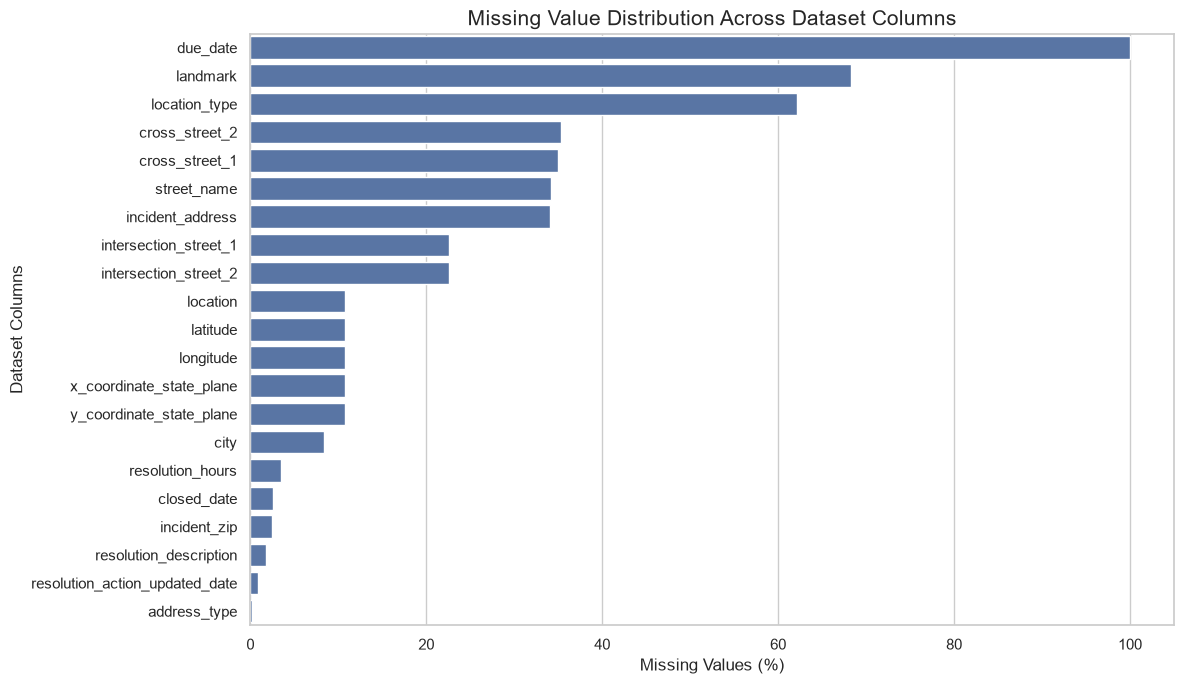

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

missing_summary.to_csv(
    EDA_TABLES_DIR / "missing_values_summary.csv"
)

plot_data = missing_summary[
    missing_summary["Missing Count"] > 0
]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.title(
    "Missing Value Distribution Across Dataset Columns",
    fontsize=15
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset Columns")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "missing_values_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
missing_analysis = missing_summary.copy()

def classify_missingness(column):

    if column == "due_date":
        return "Completely Empty"

    elif column in [
        "latitude",
        "longitude",
        "location",
        "resolution_hours",
        "closed_date"
    ]:
        return "Analytically Important"

    elif column in [
        "created_date",
        "complaint_type",
        "borough",
        "unique_key"
    ]:
        return "Core Fields"

    else:
        return "Descriptive Fields"


missing_analysis["Field Group"] = (
    missing_analysis.index.map(classify_missingness)
)

display(
    missing_analysis[
        missing_analysis["Missing Count"] > 0
    ]
)

,Missing Count,Missing Percentage,Field Group
due_date,100000,100.00,Completely Empty
landmark,68280,68.28,Descriptive Fields
location_type,62163,62.16,Descriptive Fields
cross_street_2,35327,35.33,Descriptive Fields
cross_street_1,34955,34.96,Descriptive Fields
street_name,34122,34.12,Descriptive Fields
incident_address,34117,34.12,Descriptive Fields
intersection_street_1,22631,22.63,Descriptive Fields
intersection_street_2,22610,22.61,Descriptive Fields
location,10756,10.76,Analytically Important


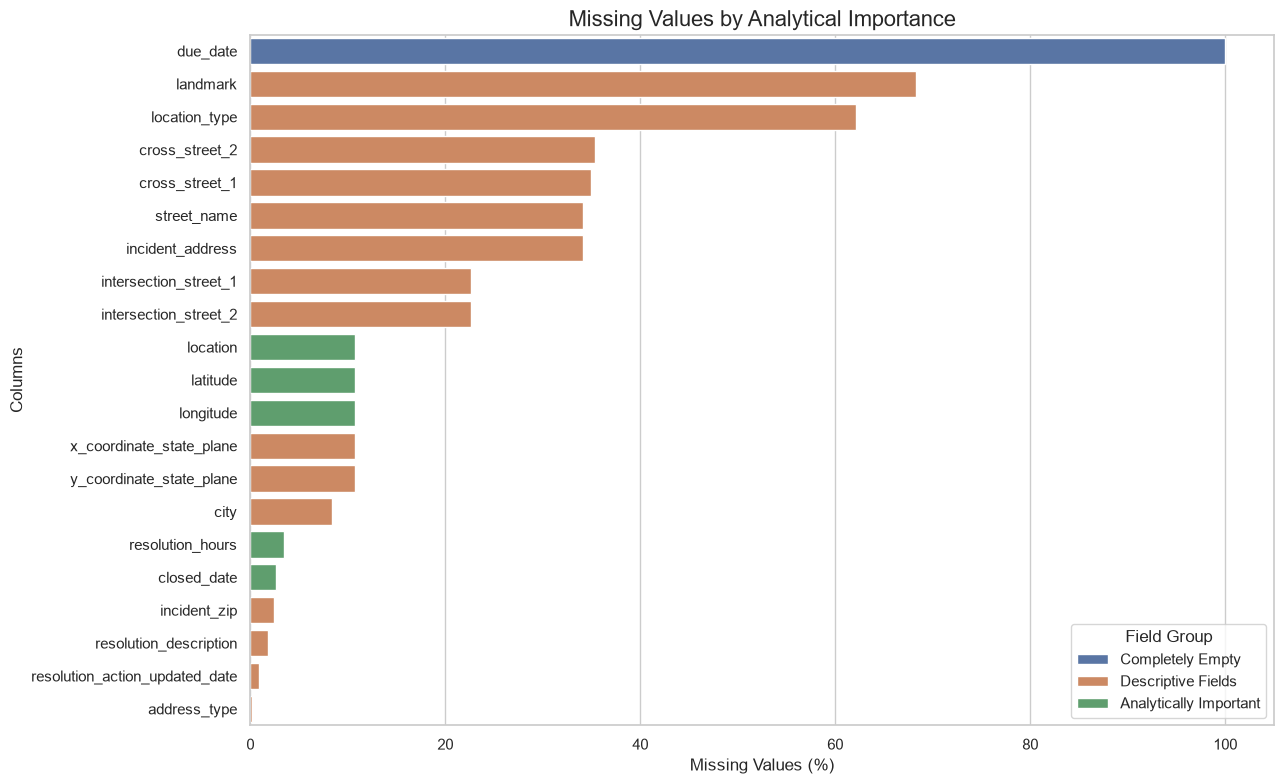

In [12]:
plot_df = missing_analysis[
    missing_analysis["Missing Count"] > 0
].copy()

plt.figure(figsize=(13, 8))

sns.barplot(
    data=plot_df.reset_index(),
    x="Missing Percentage",
    y="index",
    hue="Field Group",
    dodge=False
)

plt.title(
    "Missing Values by Analytical Importance",
    fontsize=16
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "missingness_by_field_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
quality_findings = [
    "The cleaned dataset contains 100,000 complaint records.",
    "The dataset contains 41 columns.",
    "All complaint identifiers are unique.",
    "No missing complaint identifiers were found.",
    "No missing complaint creation dates were found.",
    "Due date is completely empty and provides no analytical value.",
    "Latitude and longitude are missing in 10.76% of records.",
    "Resolution duration is missing in 3.47% of records.",
    "The dataset contains 15 complaint categories.",
    "Geographic analysis should use records with valid coordinate pairs."
]

report_path = REPORTS_DIR / "eda_data_quality_findings.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write("EDA — DATA QUALITY FINDINGS\n")
    file.write("=" * 50 + "\n\n")

    for index, finding in enumerate(
        quality_findings, start=1
    ):
        file.write(f"{index}. {finding}\n")

print("EDA findings saved:", report_path)

EDA findings saved: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\reports\eda_data_quality_findings.txt


### Section 2: Complaint Category Analysis

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [15]:
print("Number of unique complaint categories:",
      df["complaint_type"].nunique())

print("\nAvailable categories:")

print(
    sorted(df["complaint_type"].dropna().unique())
)

Number of unique complaint categories: 15

Available categories:
['Bridge Condition', 'Curb Condition', 'Root/Sewer/Sidewalk Condition', 'Sewer', 'Sewer Maintenance', 'Sidewalk Condition', 'Street Condition', 'Street Light Condition', 'Street Sign - Damaged', 'Street Sign - Dangling', 'Street Sign - Missing', 'Traffic Signal Condition', 'Water Drainage', 'Water Leak', 'Water Maintenance']


In [16]:
category_summary = (
    df["complaint_type"]
    .value_counts()
    .reset_index()
)

category_summary.columns = [
    "complaint_category",
    "complaint_count"
]

category_summary["percentage"] = (
    category_summary["complaint_count"]
    / len(df) * 100
).round(2)

category_summary["cumulative_percentage"] = (
    category_summary["percentage"].cumsum()
).round(2)

display(category_summary)

,complaint_category,complaint_count,percentage,cumulative_percentage
0,Street Condition,30006,30.01,30.01
1,Traffic Signal Condition,18896,18.90,48.91
2,Street Light Condition,14485,14.49,63.40
3,Sewer,12000,12.00,75.40
4,Sidewalk Condition,10772,10.77,86.17
5,Root/Sewer/Sidewalk Condition,4404,4.40,90.57
6,Curb Condition,3097,3.10,93.67
7,Street Sign - Damaged,2188,2.19,95.86
8,Street Sign - Dangling,1544,1.54,97.40
9,Street Sign - Missing,1521,1.52,98.92


In [17]:
category_summary.to_csv(
    EDA_TABLES_DIR / "category_summary.csv",
    index=False
)

print("Category summary saved successfully.")

Category summary saved successfully.


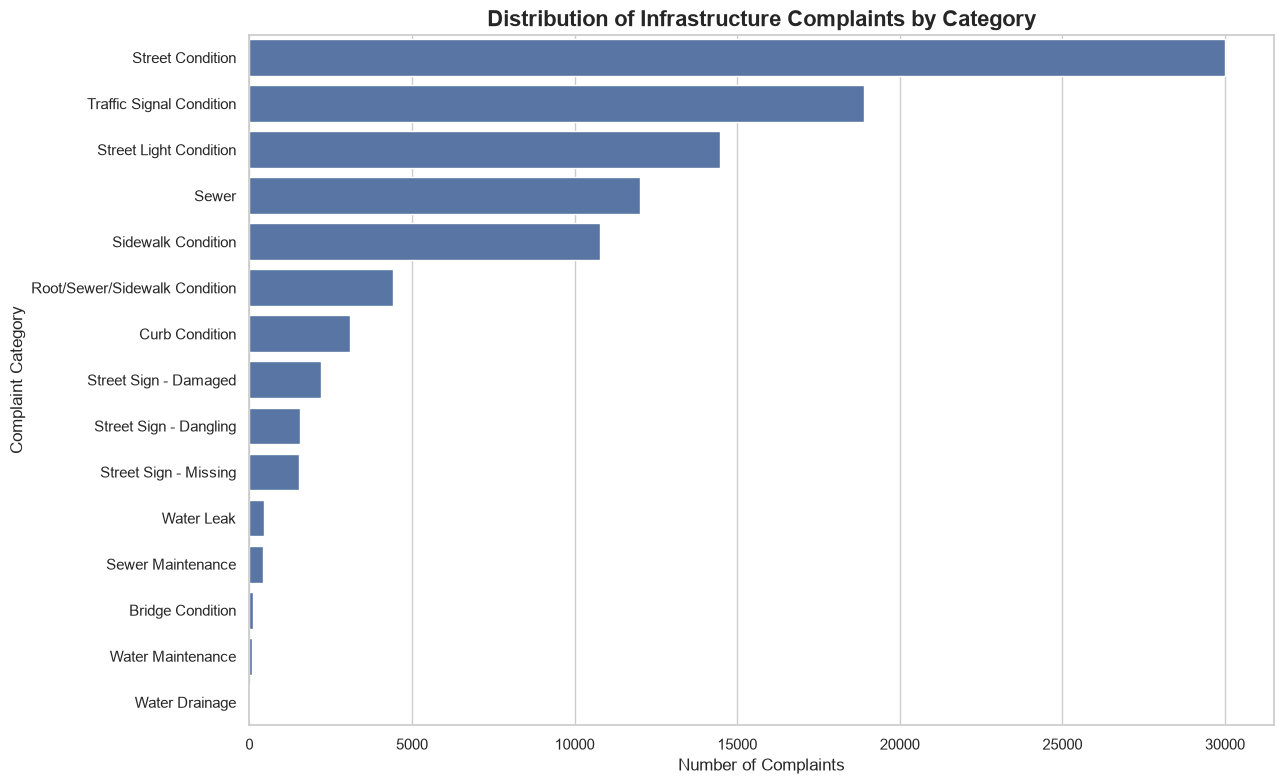

In [18]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=category_summary,
    x="complaint_count",
    y="complaint_category"
)

plt.title(
    "Distribution of Infrastructure Complaints by Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "complaint_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

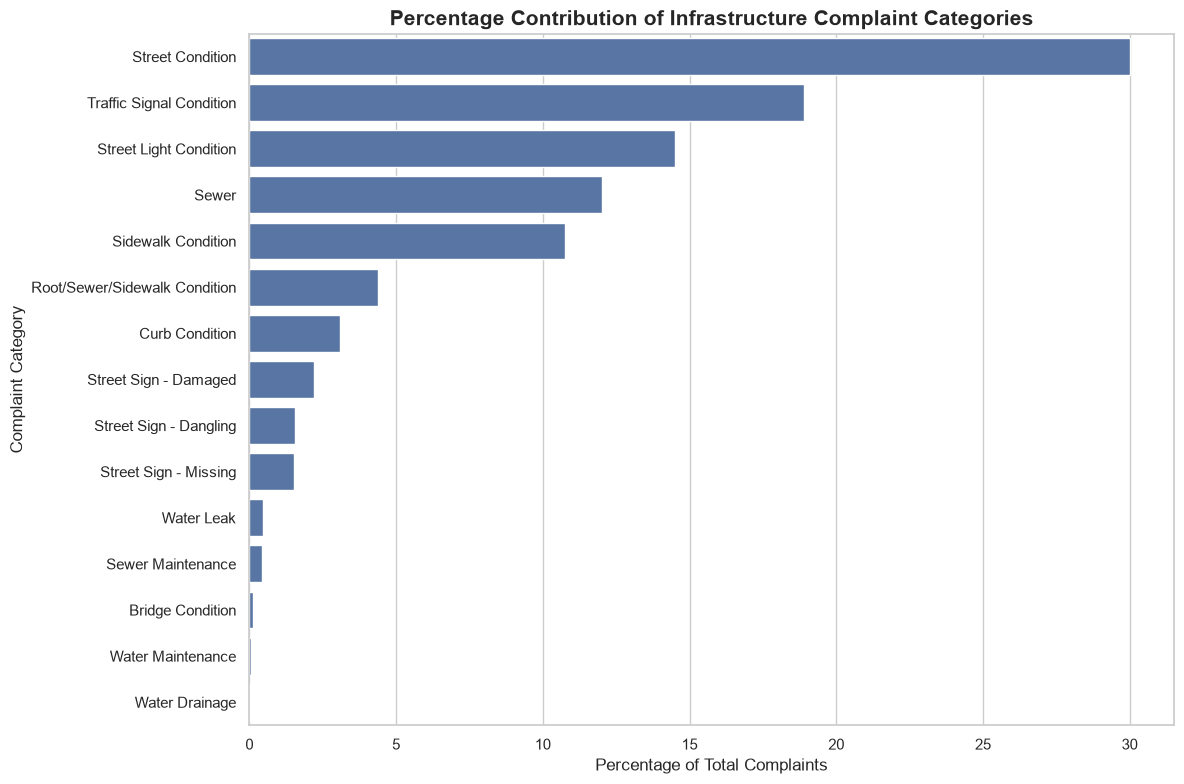

In [19]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=category_summary,
    x="percentage",
    y="complaint_category"
)

plt.title(
    "Percentage Contribution of Infrastructure Complaint Categories",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Percentage of Total Complaints")
plt.ylabel("Complaint Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "category_percentage_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

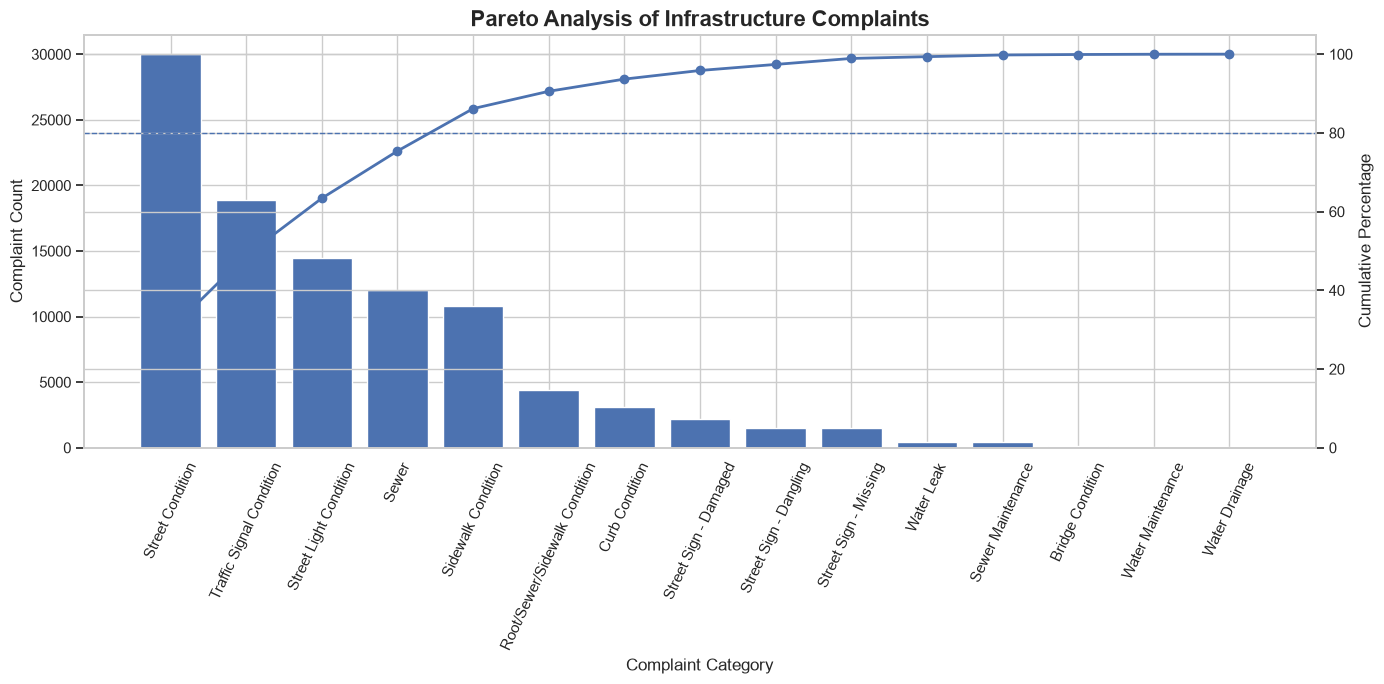

In [20]:
fig, ax1 = plt.subplots(figsize=(14, 7))

categories = category_summary["complaint_category"]
counts = category_summary["complaint_count"]
cumulative = category_summary["cumulative_percentage"]

ax1.bar(
    categories,
    counts
)

ax1.set_xlabel("Complaint Category")
ax1.set_ylabel("Complaint Count")

ax1.tick_params(
    axis="x",
    rotation=65
)

ax2 = ax1.twinx()

ax2.plot(
    categories,
    cumulative,
    marker="o",
    linewidth=2
)

ax2.set_ylabel("Cumulative Percentage")
ax2.set_ylim(0, 105)

ax2.axhline(
    80,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Pareto Analysis of Infrastructure Complaints",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "complaint_category_pareto.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify dominant and underrepresented categories

In [21]:
highest_category = category_summary.iloc[0]

lowest_category = category_summary.iloc[-1]

print("CATEGORY ANALYSIS")
print("=" * 55)

print(
    f"\nHighest complaint category: "
    f"{highest_category['complaint_category']}"
)

print(
    f"Complaint count: "
    f"{highest_category['complaint_count']:,}"
)

print(
    f"Contribution: "
    f"{highest_category['percentage']}%"
)

print("\n")

print(
    f"Lowest complaint category: "
    f"{lowest_category['complaint_category']}"
)

print(
    f"Complaint count: "
    f"{lowest_category['complaint_count']:,}"
)

print(
    f"Contribution: "
    f"{lowest_category['percentage']}%"
)

CATEGORY ANALYSIS

Highest complaint category: Street Condition
Complaint count: 30,006
Contribution: 30.01%


Lowest complaint category: Water Drainage
Complaint count: 20
Contribution: 0.02%


Category concentration summary

In [22]:
top_3_percentage = (
    category_summary.head(3)["percentage"].sum()
)

top_5_percentage = (
    category_summary.head(5)["percentage"].sum()
)

print("CATEGORY CONCENTRATION")
print("=" * 45)

print(f"Top 3 categories: {top_3_percentage:.2f}%")
print(f"Top 5 categories: {top_5_percentage:.2f}%")

print(
    "\nRemaining categories:",
    15 - 5
)

CATEGORY CONCENTRATION
Top 3 categories: 63.40%
Top 5 categories: 86.17%

Remaining categories: 10


In [23]:
category_findings = {
    "total_records": len(df),
    "total_categories": df["complaint_type"].nunique(),
    "highest_category": highest_category["complaint_category"],
    "highest_category_count": int(
        highest_category["complaint_count"]
    ),
    "lowest_category": lowest_category["complaint_category"],
    "lowest_category_count": int(
        lowest_category["complaint_count"]
    ),
    "top_3_contribution_pct": round(top_3_percentage, 2),
    "top_5_contribution_pct": round(top_5_percentage, 2)
}

category_findings_df = pd.DataFrame(
    [category_findings]
)

display(category_findings_df)

category_findings_df.to_csv(
    EDA_TABLES_DIR / "category_analysis_findings.csv",
    index=False
)

,total_records,total_categories,highest_category,highest_category_count,lowest_category,lowest_category_count,top_3_contribution_pct,top_5_contribution_pct
0,100000,15,Street Condition,30006,Water Drainage,20,63.40,86.17


# Section 2: Complaint Category Analysis 

## 1. Key Findings

### Finding 1: Street Condition Dominates

Street Condition is the most frequently reported infrastructure complaint category, accounting for approximately **30% of the total 100,000 records**.

This indicates that road-related complaints are strongly represented in the extracted dataset.

### Finding 2: Complaint Distribution Is Highly Concentrated

The top three complaint categories contribute **63.40%** of all records, while the top five categories account for **86.17%**.

This indicates that complaint records are concentrated in a relatively small number of infrastructure categories.

This imbalance must be considered during feature engineering and K-Means clustering because categories with different complaint volumes may have different numerical scales.

### Finding 3: Some Categories Are Underrepresented

Water Drainage has only **20 records**, making it the least represented category.

Bridge Condition and Water Maintenance are also relatively rare.

Although these categories should not automatically be removed, their low representation may limit the reliability of category-specific geographic patterns.

### Finding 4: Importance of Geographic Complaint Profiles

For infrastructure health profiling, two types of geographic features will be important:

* **Absolute Complaint Counts:** The total number of complaints reported in a particular geographic area.
* **Normalized Complaint Composition:** The proportion of complaints belonging to each infrastructure category within that area.

Using both measurements will help distinguish areas with generally high complaint activity from areas dominated by specific infrastructure complaint types.

---

## 2. Project Implications

The category distribution reveals substantial differences in complaint frequency across infrastructure types.

Before applying K-Means, we must carefully consider feature scaling and category representation to prevent high-frequency categories from dominating the clustering results.

Rare categories will require additional investigation before deciding whether they should be included in the main clustering model.

## 3. Conclusion

The category analysis provides an initial understanding of the infrastructure complaint composition of New York City.

Street Condition, Traffic Signal Condition, Street Light Condition, Sewer, and Sidewalk Condition are the five most frequently represented categories.

These findings provide a foundation for subsequent temporal and geographic analysis and the development of geographic infrastructure health profiles using unsupervised machine learning.


## Section 3: Temporal Complaint Analysis

#### Prepare temporal feature

In [24]:
# Ensure datetime format
df["created_date"] = pd.to_datetime(
    df["created_date"],
    errors="coerce"
)

# Extract temporal features
df["year"] = df["created_date"].dt.year
df["month"] = df["created_date"].dt.month
df["month_name"] = df["created_date"].dt.month_name()
df["day_of_week"] = df["created_date"].dt.dayofweek
df["day_name"] = df["created_date"].dt.day_name()

df["year_month"] = (
    df["created_date"].dt.to_period("M").astype(str)
)

print("Temporal features created successfully.")

display(df[[
    "created_date",
    "year",
    "month",
    "month_name",
    "day_name",
    "year_month"
]].head())

Temporal features created successfully.


,created_date,year,month,month_name,day_name,year_month
0,2023-01-01 02:51:00,2023,1,January,Sunday,2023-01
1,2023-01-01 03:33:00,2023,1,January,Sunday,2023-01
2,2023-01-01 07:53:00,2023,1,January,Sunday,2023-01
3,2023-01-01 07:59:00,2023,1,January,Sunday,2023-01
4,2023-01-01 10:29:31,2023,1,January,Sunday,2023-01


#### Year-wise complaint analysis

In [25]:
yearly_summary = (
    df.groupby("year")
    .size()
    .reset_index(name="complaint_count")
)

yearly_summary["percentage"] = (
    yearly_summary["complaint_count"] / len(df) * 100
).round(2)

display(yearly_summary)

,year,complaint_count,percentage
0,2023,32660,32.66
1,2024,32993,32.99
2,2025,34347,34.35


In [26]:
yearly_summary.to_csv(
    EDA_TABLES_DIR / "yearly_complaint_summary.csv",
    index=False
)

Year-wise distribution

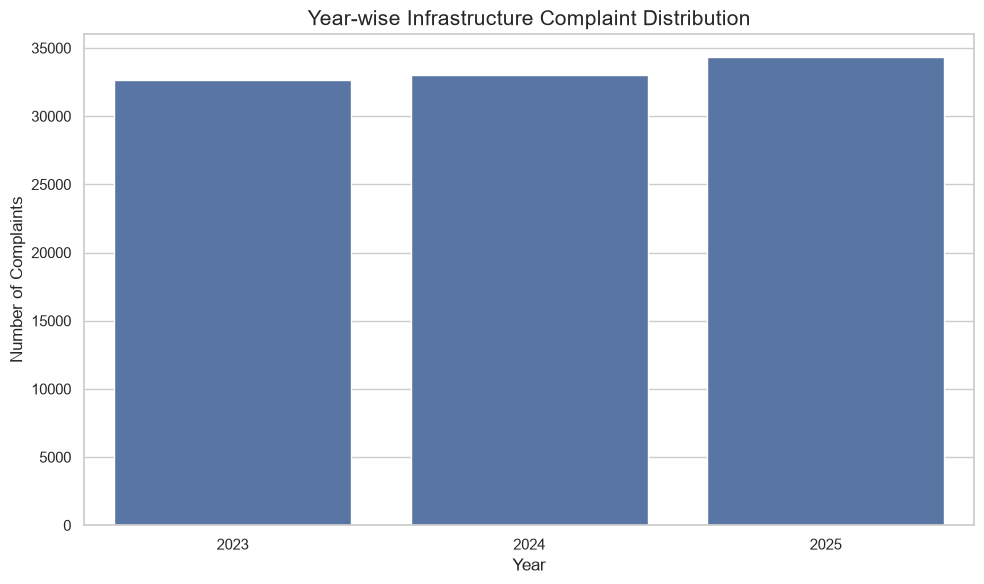

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=yearly_summary,
    x="year",
    y="complaint_count"
)

plt.title(
    "Year-wise Infrastructure Complaint Distribution",
    fontsize=15
)

plt.xlabel("Year")
plt.ylabel("Number of Complaints")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "yearly_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Monthly complaint trends

In [28]:
monthly_summary = (
    df.groupby("year_month")
    .size()
    .reset_index(name="complaint_count")
)

monthly_summary["month_date"] = pd.to_datetime(
    monthly_summary["year_month"]
)

monthly_summary = monthly_summary.sort_values(
    "month_date"
)

display(monthly_summary)

,year_month,complaint_count,month_date
0,2023-01,2977,2023-01-01
1,2023-02,2657,2023-02-01
2,2023-03,3157,2023-03-01
3,2023-04,2667,2023-04-01
4,2023-05,2628,2023-05-01
5,2023-06,2368,2023-06-01
6,2023-07,2528,2023-07-01
7,2023-08,2726,2023-08-01
8,2023-09,3483,2023-09-01
9,2023-10,2940,2023-10-01


In [29]:
monthly_summary.to_csv(
    EDA_TABLES_DIR / "monthly_complaint_summary.csv",
    index=False
)

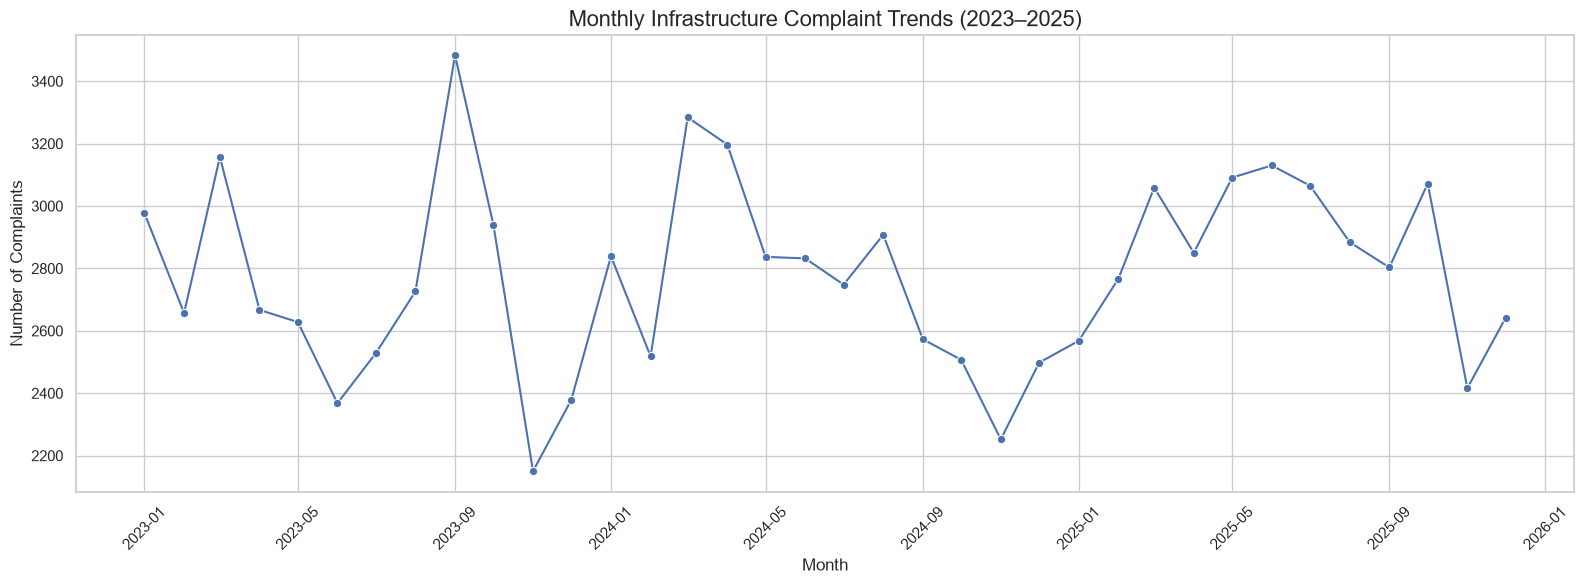

In [30]:
plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_summary,
    x="month_date",
    y="complaint_count",
    marker="o"
)

plt.title(
    "Monthly Infrastructure Complaint Trends (2023–2025)",
    fontsize=16
)

plt.xlabel("Month")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "monthly_complaint_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Seasonal complaint analysis

In [31]:
month_order = [
    "January", "February", "March",
    "April", "May", "June",
    "July", "August", "September",
    "October", "November", "December"
]

seasonal_summary = (
    df.groupby("month_name")
    .size()
    .reindex(month_order)
    .reset_index()
)

seasonal_summary.columns = [
    "month_name",
    "complaint_count"
]

display(seasonal_summary)

,month_name,complaint_count
0,January,8384
1,February,7942
2,March,9500
3,April,8714
4,May,8556
5,June,8330
6,July,8341
7,August,8518
8,September,8859
9,October,8519


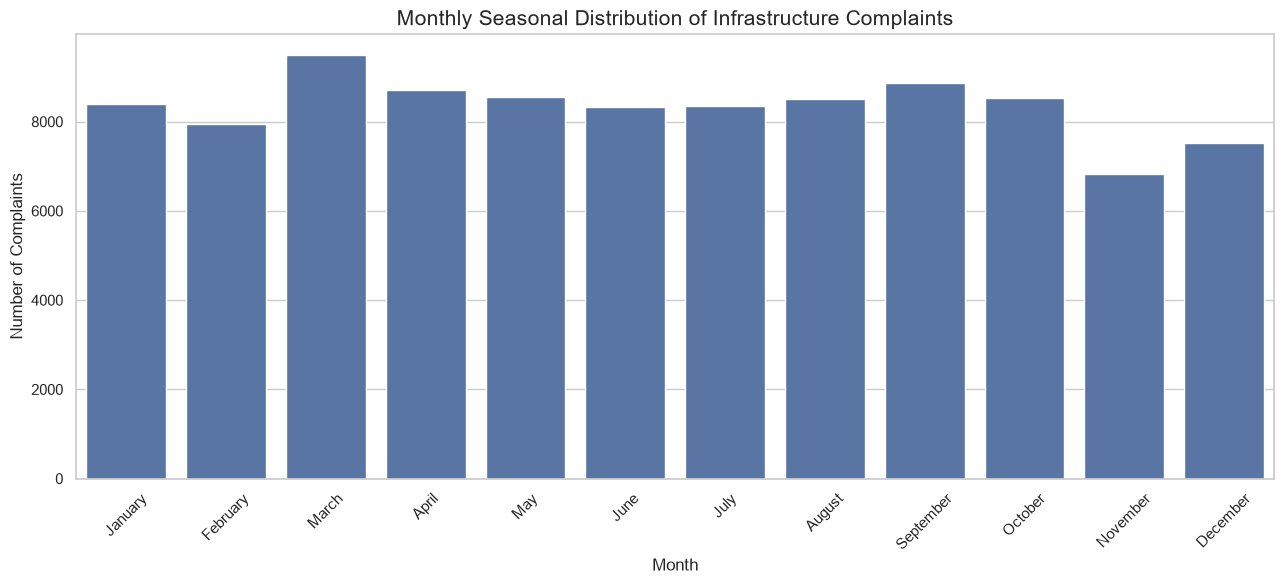

In [32]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=seasonal_summary,
    x="month_name",
    y="complaint_count"
)

plt.title(
    "Monthly Seasonal Distribution of Infrastructure Complaints",
    fontsize=15
)

plt.xlabel("Month")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "seasonal_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Weekday analysis

In [33]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df.groupby("day_name")
    .size()
    .reindex(weekday_order)
    .reset_index()
)

weekday_summary.columns = [
    "day_name",
    "complaint_count"
]

weekday_summary["percentage"] = (
    weekday_summary["complaint_count"] / len(df) * 100
).round(2)

display(weekday_summary)

,day_name,complaint_count,percentage
0,Monday,16710,16.71
1,Tuesday,17375,17.38
2,Wednesday,17140,17.14
3,Thursday,16575,16.58
4,Friday,15454,15.45
5,Saturday,8425,8.43
6,Sunday,8321,8.32


In [34]:
weekday_summary.to_csv(
    EDA_TABLES_DIR / "weekday_complaint_summary.csv",
    index=False
)

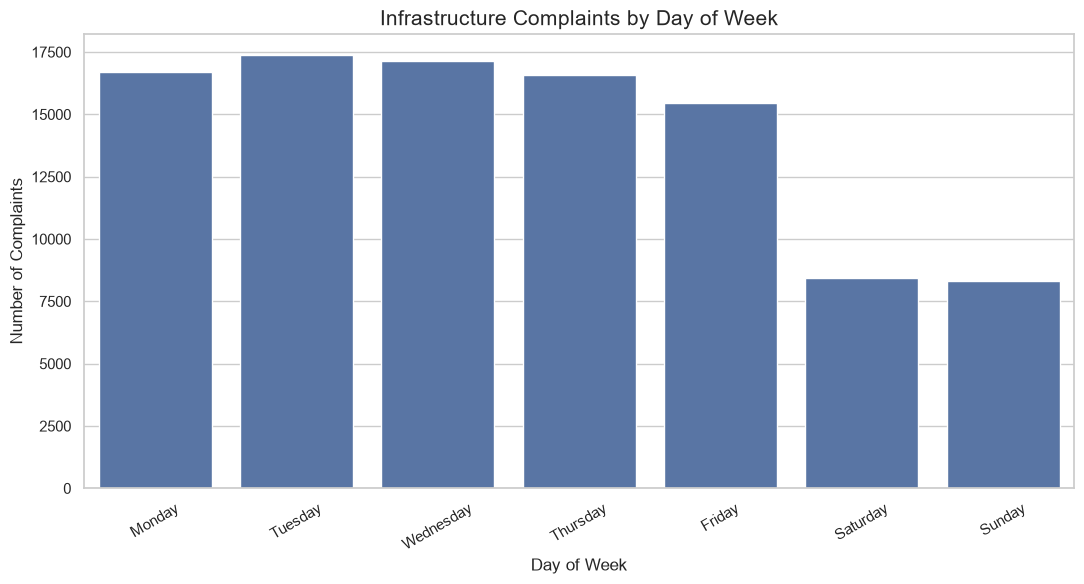

In [35]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=weekday_summary,
    x="day_name",
    y="complaint_count"
)

plt.title(
    "Infrastructure Complaints by Day of Week",
    fontsize=15
)

plt.xlabel("Day of Week")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "weekday_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
category_monthly = pd.crosstab(
    df["complaint_type"],
    df["month_name"]
)

category_monthly = category_monthly.reindex(
    columns=month_order
)

display(category_monthly)

month_name,January,February,March,April,May,June,July,August,September,October,November,December
complaint_type,,,,,,,,,,,,
Bridge Condition,12,11,15,7,15,7,13,9,7,5,10,12
Curb Condition,207,198,255,293,285,273,264,263,288,275,271,225
Root/Sewer/Sidewalk Condition,262,236,356,381,425,423,440,471,446,423,289,252
Sewer,901,656,1016,950,1072,876,1165,1270,1238,1182,781,893
Sewer Maintenance,0,0,2,1,1,2,1,1,324,92,2,2
Sidewalk Condition,700,652,872,933,980,963,1004,1030,1012,1038,848,740
Street Condition,2546,2616,3215,2894,2955,2900,2498,2363,2163,2041,1703,2112
Street Light Condition,1396,1350,1436,1267,952,914,997,1180,1264,1403,1198,1128
Street Sign - Damaged,158,169,212,210,196,188,195,177,181,172,157,173


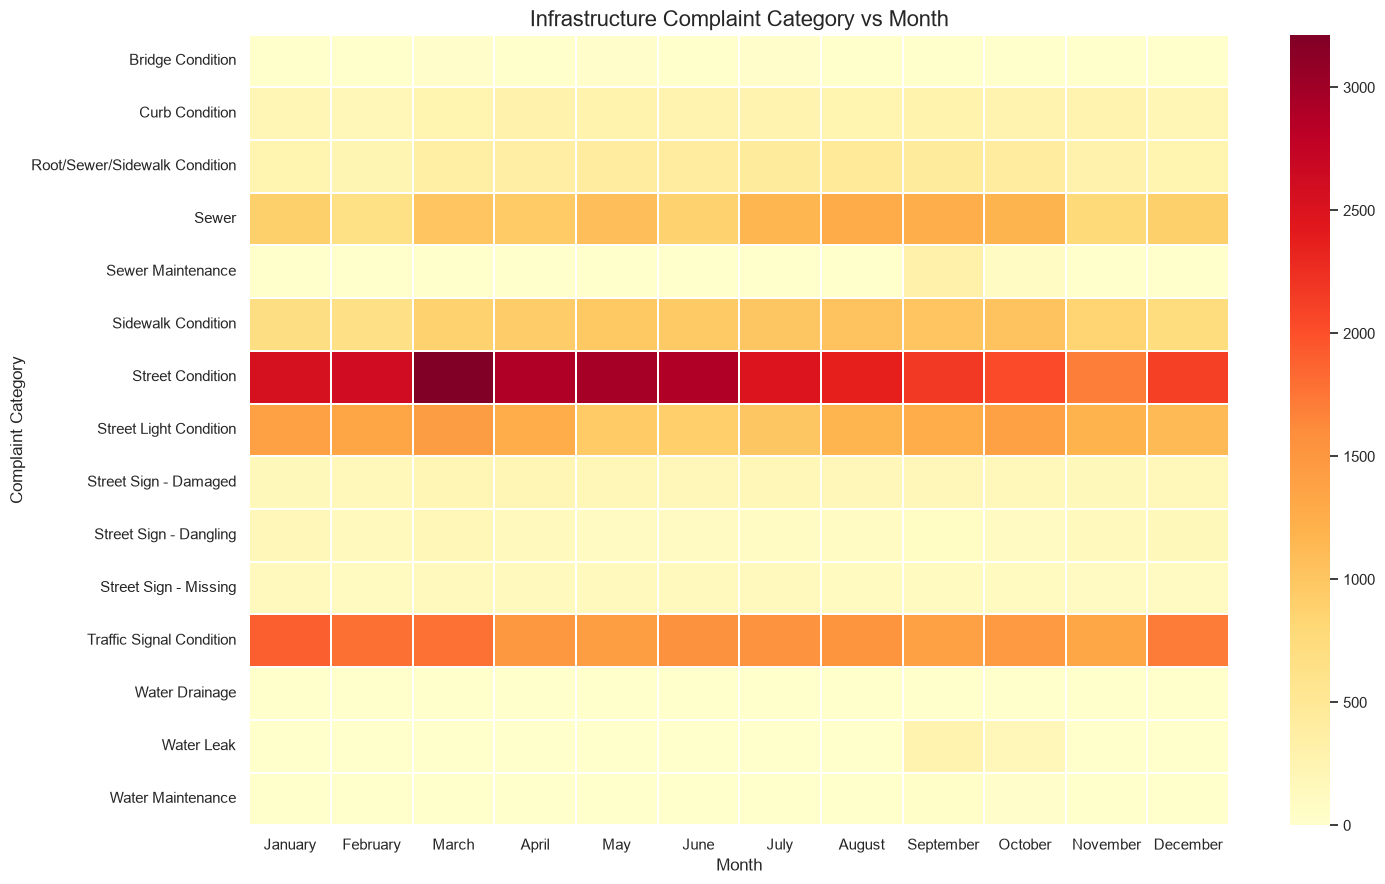

In [37]:
plt.figure(figsize=(15, 9))

sns.heatmap(
    category_monthly,
    cmap="YlOrRd",
    linewidths=0.3,
    annot=False
)

plt.title(
    "Infrastructure Complaint Category vs Month",
    fontsize=16
)

plt.xlabel("Month")
plt.ylabel("Complaint Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "category_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Section 3: Temporal Complaint Analysis

## 1. Key Findings

### Finding 1: Year-wise Complaint Distribution

The highest complaint volume was observed in 2025, with 34,347 records (34.35%). Complaint counts increased from 32,660 in 2023 to 34,347 in 2025, representing an approximate increase of 5.17%.

### Finding 2: Monthly Complaint Patterns

March recorded the highest aggregate complaint count across the three study years, with 9,500 records. November recorded the lowest aggregate count, with 6,818 records.

At the individual month level, September 2023 recorded the highest monthly complaint volume (3,483), while November 2023 recorded the lowest (2,150).

### Finding 3: Weekday Distribution

Tuesday recorded the highest complaint volume (17,375), followed by Wednesday (17,140).

Weekday complaints accounted for approximately 83.25% of the dataset, while weekend complaints accounted for approximately 16.75%.

This suggests that complaint reporting is concentrated on weekdays.

### Finding 4: Category-wise Temporal Patterns

The category-month heatmap shows that Street Condition consistently contributes substantial complaint activity across the year. Sewer, Sidewalk Condition, and Traffic Signal Condition also demonstrate variations across months.

Less frequent categories have relatively low monthly counts, limiting the interpretation of their temporal patterns.

## 2. Project Implications

Temporal patterns provide additional information for understanding geographic infrastructure complaint profiles.

Potential features for subsequent geographic aggregation include:

* Average monthly complaint volume.
* Monthly complaint variability.
* Year-over-year complaint changes.
* Seasonal complaint distribution.
* Temporal consistency of complaint activity.

These features may help distinguish geographic areas with persistent complaint activity from those experiencing occasional increases.

## 3. Limitations

The analysis is based on a 100,000-record sample of NYC 311 complaints.

Differences in complaint counts should not automatically be interpreted as changes in actual infrastructure conditions. Reporting behaviour, operational schedules, and sample composition may influence the observed patterns.

## 4. Conclusion

The temporal analysis reveals gradual annual growth, monthly fluctuations, and a strong concentration of recorded complaints on weekdays.

These findings provide a temporal foundation for subsequent geographic analysis and infrastructure health profiling using unsupervised machine learning.


### Section 4: Borough-wise Infrastructure Analysis

In [38]:
print("Unique borough values:")
print(df["borough"].value_counts(dropna=False))

print("\nNumber of unique borough values:")
print(df["borough"].nunique(dropna=True))

Unique borough values:
borough
QUEENS           32805
BROOKLYN         30468
MANHATTAN        15558
BRONX            12550
STATEN ISLAND     8360
Unspecified        259
Name: count, dtype: int64

Number of unique borough values:
6


In [39]:
borough_df = df.copy()

borough_df["borough_analysis"] = (
    borough_df["borough"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
    .replace("", "Missing")
)

print("Borough analysis dataset:", borough_df.shape)

display(
    borough_df["borough_analysis"]
    .value_counts()
    .rename_axis("borough")
    .reset_index(name="complaint_count")
)

Borough analysis dataset: (100000, 48)


,borough,complaint_count
0,QUEENS,32805
1,BROOKLYN,30468
2,MANHATTAN,15558
3,BRONX,12550
4,STATEN ISLAND,8360
5,Unspecified,259


In [40]:
borough_summary = (
    borough_df["borough_analysis"]
    .value_counts()
    .reset_index()
)

borough_summary.columns = [
    "borough",
    "complaint_count"
]

borough_summary["percentage"] = (
    borough_summary["complaint_count"]
    / len(borough_df) * 100
).round(2)

display(borough_summary)

,borough,complaint_count,percentage
0,QUEENS,32805,32.80
1,BROOKLYN,30468,30.47
2,MANHATTAN,15558,15.56
3,BRONX,12550,12.55
4,STATEN ISLAND,8360,8.36
5,Unspecified,259,0.26


In [41]:
borough_summary.to_csv(
    EDA_TABLES_DIR / "borough_complaint_summary.csv",
    index=False
)

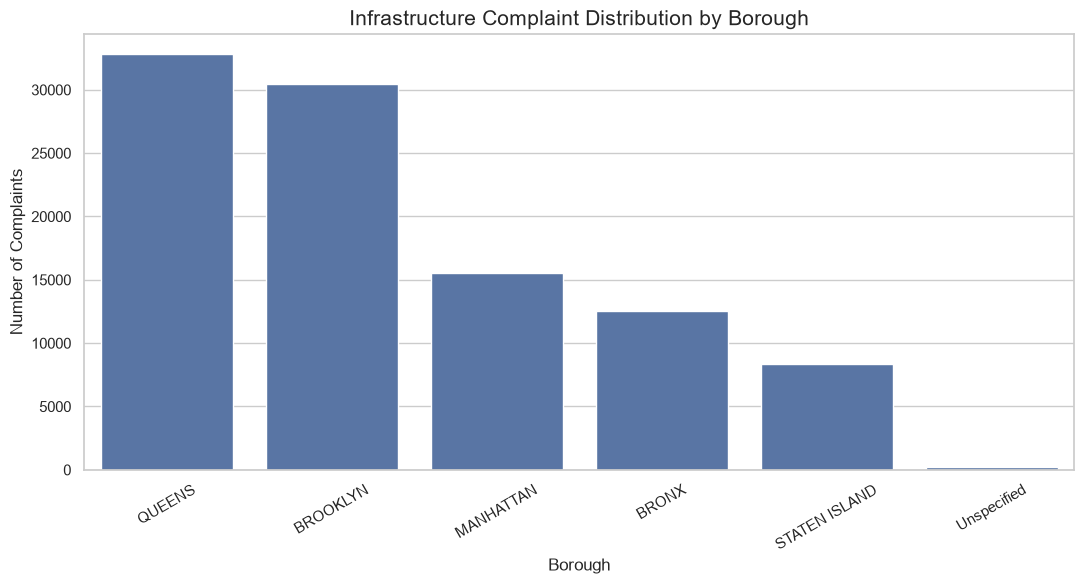

In [42]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=borough_summary,
    x="borough",
    y="complaint_count"
)

plt.title(
    "Infrastructure Complaint Distribution by Borough",
    fontsize=15
)

plt.xlabel("Borough")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "borough_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Complaint category distribution within each borough

In [43]:
borough_category = pd.crosstab(
    borough_df["borough_analysis"],
    borough_df["complaint_type"]
)

display(borough_category)

complaint_type,Bridge Condition,Curb Condition,Root/Sewer/Sidewalk Condition,Sewer,Sewer Maintenance,Sidewalk Condition,Street Condition,Street Light Condition,Street Sign - Damaged,Street Sign - Dangling,Street Sign - Missing,Traffic Signal Condition,Water Drainage,Water Leak,Water Maintenance
borough_analysis,,,,,,,,,,,,,,,
BRONX,10,232,443,1400,43,1089,3007,2862,261,220,175,2684,6,103,15
BROOKLYN,42,1352,1468,3623,202,3875,7829,3911,547,393,458,6565,5,177,21
MANHATTAN,43,515,120,894,6,1703,5352,2565,318,218,232,3489,3,93,7
QUEENS,26,869,1652,4849,145,3373,10790,3863,884,545,545,5175,4,69,16
STATEN ISLAND,2,126,721,1231,29,724,2964,1212,178,167,110,886,2,2,6
Unspecified,0,3,0,3,3,8,64,72,0,1,1,97,0,5,2


In [44]:
borough_category.to_csv(
    EDA_TABLES_DIR / "borough_category_counts.csv"
)

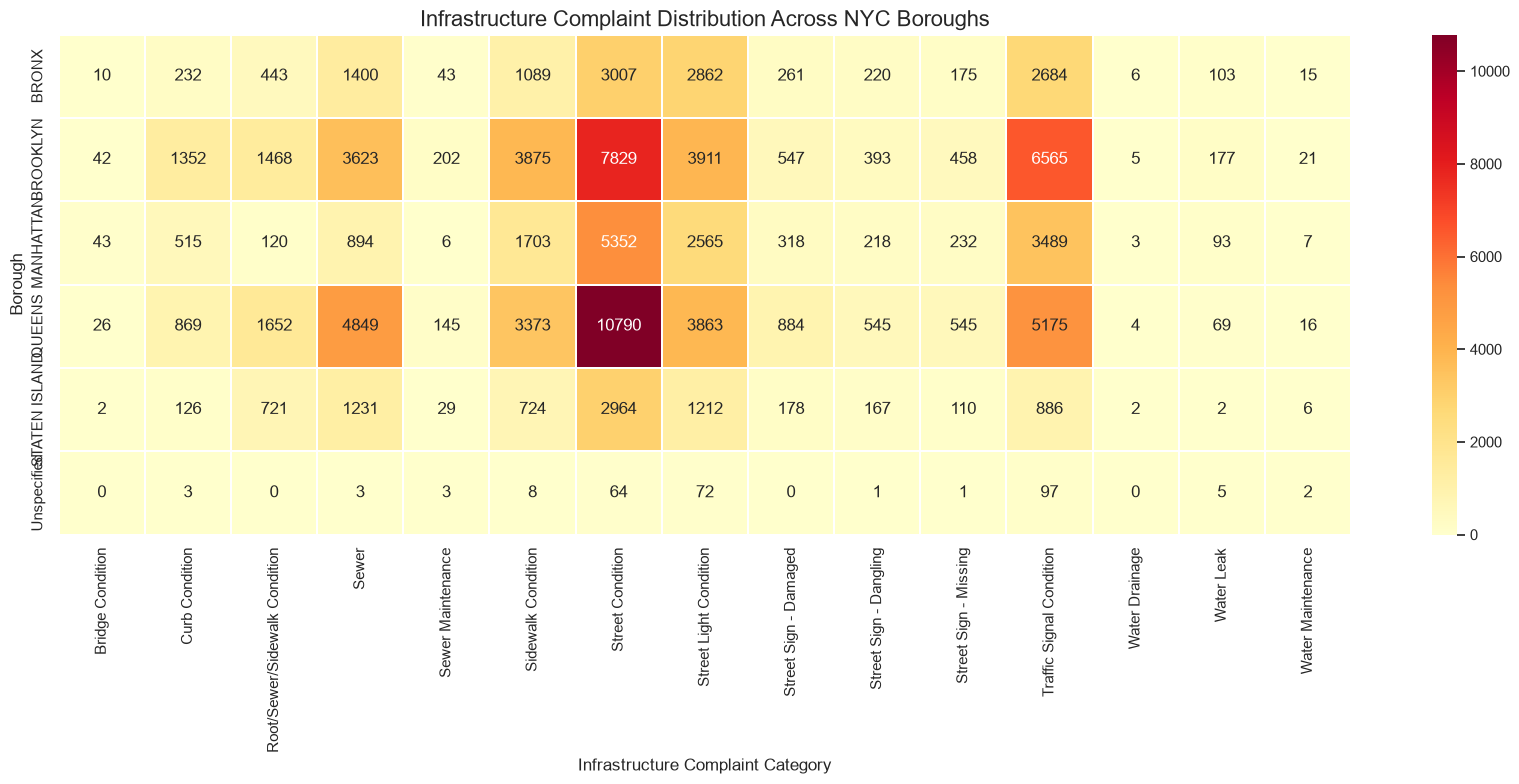

In [45]:
plt.figure(figsize=(17, 8))

sns.heatmap(
    borough_category,
    cmap="YlOrRd",
    linewidths=0.3,
    annot=True,
    fmt="d"
)

plt.title(
    "Infrastructure Complaint Distribution Across NYC Boroughs",
    fontsize=16
)

plt.xlabel("Infrastructure Complaint Category")
plt.ylabel("Borough")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "borough_category_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
borough_category_percentage = (
    borough_category
    .div(
        borough_category.sum(axis=1),
        axis=0
    ) * 100
)

display(
    borough_category_percentage.round(2)
)

complaint_type,Bridge Condition,Curb Condition,Root/Sewer/Sidewalk Condition,Sewer,Sewer Maintenance,Sidewalk Condition,Street Condition,Street Light Condition,Street Sign - Damaged,Street Sign - Dangling,Street Sign - Missing,Traffic Signal Condition,Water Drainage,Water Leak,Water Maintenance
borough_analysis,,,,,,,,,,,,,,,
BRONX,0.08,1.85,3.53,11.16,0.34,8.68,23.96,22.80,2.08,1.75,1.39,21.39,0.05,0.82,0.12
BROOKLYN,0.14,4.44,4.82,11.89,0.66,12.72,25.70,12.84,1.80,1.29,1.50,21.55,0.02,0.58,0.07
MANHATTAN,0.28,3.31,0.77,5.75,0.04,10.95,34.40,16.49,2.04,1.40,1.49,22.43,0.02,0.60,0.04
QUEENS,0.08,2.65,5.04,14.78,0.44,10.28,32.89,11.78,2.69,1.66,1.66,15.78,0.01,0.21,0.05
STATEN ISLAND,0.02,1.51,8.62,14.72,0.35,8.66,35.45,14.50,2.13,2.00,1.32,10.60,0.02,0.02,0.07
Unspecified,0.00,1.16,0.00,1.16,1.16,3.09,24.71,27.80,0.00,0.39,0.39,37.45,0.00,1.93,0.77


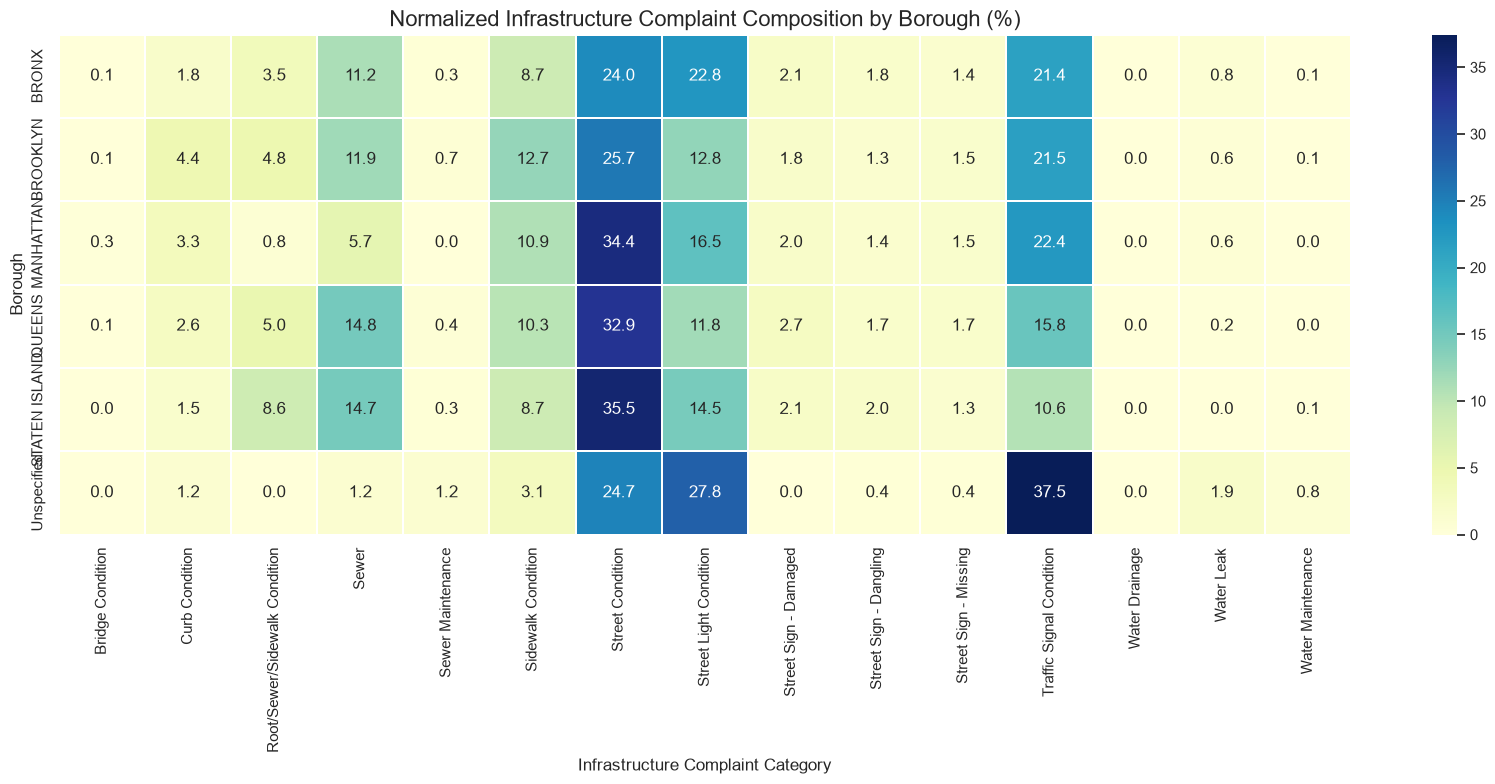

In [47]:
plt.figure(figsize=(17, 8))

sns.heatmap(
    borough_category_percentage,
    cmap="YlGnBu",
    linewidths=0.3,
    annot=True,
    fmt=".1f"
)

plt.title(
    "Normalized Infrastructure Complaint Composition by Borough (%)",
    fontsize=16
)

plt.xlabel("Infrastructure Complaint Category")
plt.ylabel("Borough")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "borough_category_percentage_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify the dominant infrastructure category in each borough

In [48]:
dominant_category = pd.DataFrame({
    "dominant_category": borough_category.idxmax(axis=1),
    "complaint_count": borough_category.max(axis=1),
    "percentage": borough_category_percentage.max(axis=1)
})

dominant_category = dominant_category.reset_index()

dominant_category.columns = [
    "borough",
    "dominant_category",
    "complaint_count",
    "percentage"
]

display(dominant_category)

,borough,dominant_category,complaint_count,percentage
0,BRONX,Street Condition,3007,23.96
1,BROOKLYN,Street Condition,7829,25.70
2,MANHATTAN,Street Condition,5352,34.40
3,QUEENS,Street Condition,10790,32.89
4,STATEN ISLAND,Street Condition,2964,35.45
5,Unspecified,Traffic Signal Condition,97,37.45


In [49]:
dominant_category.to_csv(
    EDA_TABLES_DIR / "dominant_category_by_borough.csv",
    index=False
)

In [50]:
nyc_boroughs = [
    "BROOKLYN",
    "QUEENS",
    "MANHATTAN",
    "BRONX",
    "STATEN ISLAND"
]

borough_normalized = (
    borough_df["borough_analysis"]
    .str.upper()
    .str.strip()
)

valid_borough_df = borough_df[
    borough_normalized.isin(nyc_boroughs)
].copy()

print("Total records:", len(borough_df))

print("Records belonging to five official boroughs:",
      len(valid_borough_df))

print("Excluded from five-borough comparison:",
      len(borough_df) - len(valid_borough_df))

Total records: 100000
Records belonging to five official boroughs: 99741
Excluded from five-borough comparison: 259


Compare category composition across official boroughs

In [51]:
official_borough_category = pd.crosstab(
    valid_borough_df["borough_analysis"].str.title(),
    valid_borough_df["complaint_type"]
)

official_borough_percentage = (
    official_borough_category
    .div(
        official_borough_category.sum(axis=1),
        axis=0
    ) * 100
)

display(official_borough_percentage.round(2))

complaint_type,Bridge Condition,Curb Condition,Root/Sewer/Sidewalk Condition,Sewer,Sewer Maintenance,Sidewalk Condition,Street Condition,Street Light Condition,Street Sign - Damaged,Street Sign - Dangling,Street Sign - Missing,Traffic Signal Condition,Water Drainage,Water Leak,Water Maintenance
borough_analysis,,,,,,,,,,,,,,,
Bronx,0.08,1.85,3.53,11.16,0.34,8.68,23.96,22.80,2.08,1.75,1.39,21.39,0.05,0.82,0.12
Brooklyn,0.14,4.44,4.82,11.89,0.66,12.72,25.70,12.84,1.80,1.29,1.50,21.55,0.02,0.58,0.07
Manhattan,0.28,3.31,0.77,5.75,0.04,10.95,34.40,16.49,2.04,1.40,1.49,22.43,0.02,0.60,0.04
Queens,0.08,2.65,5.04,14.78,0.44,10.28,32.89,11.78,2.69,1.66,1.66,15.78,0.01,0.21,0.05
Staten Island,0.02,1.51,8.62,14.72,0.35,8.66,35.45,14.50,2.13,2.00,1.32,10.60,0.02,0.02,0.07


In [52]:
official_borough_percentage.to_csv(
    EDA_TABLES_DIR / "official_borough_category_composition.csv"
)

# Section 4: Borough-wise Infrastructure Analysis

## 1. Key Findings

### Finding 1: Borough Complaint Distribution

Queens recorded the highest complaint volume with 32,805 records (32.80%), followed by Brooklyn with 30,468 records (30.47%).

Staten Island recorded the lowest complaint volume among the five official boroughs, with 8,360 records (8.36%).

Queens and Brooklyn together contributed approximately 63.27% of all complaint records.

### Finding 2: Street Condition Dominates Across Boroughs

Street Condition was the dominant complaint category in all five official boroughs.

Its contribution ranged from 23.96% in the Bronx to 35.45% in Staten Island.

### Finding 3: Differences in Infrastructure Complaint Composition

The normalized heatmap revealed several distinctive patterns:

* The Bronx has a relatively high proportion of Street Light Condition complaints (22.80%).
* Manhattan has the highest proportion of Street Condition complaints (34.40%).
* Queens has a relatively high proportion of Sewer complaints (14.78%).
* Staten Island has a high proportion of Street Condition (35.45%) and Sewer complaints (14.72%).
* Brooklyn has a relatively balanced contribution from Street Condition (25.70%), Traffic Signal Condition (21.55%), and Street Light Condition (12.84%).

### Finding 4: Geographic Differences in Complaint Profiles

Although Street Condition dominates across all five boroughs, the relative contributions of other infrastructure categories vary.

These differences suggest that geographic areas may exhibit distinct infrastructure complaint profiles.

## 2. Project Implications

Borough-level analysis provides an initial understanding of geographic differences in infrastructure complaint patterns.

For the proposed K-Means health profiling model, we will eventually construct geographic feature vectors containing:

* Complaint counts by infrastructure category.
* Normalized category proportions.
* Total complaint intensity.
* Temporal complaint characteristics.
* Geographic information.

Both absolute counts and normalized proportions will be considered to avoid allowing high-volume areas to dominate clustering simply because they have more complaint records.

## 3. Limitations

The analysis uses complaint counts rather than population-adjusted or infrastructure-adjusted rates.

Consequently, a higher complaint count does not necessarily indicate worse infrastructure conditions.

The dataset also contains 259 records with unspecified borough information. These records were retained in the overall analysis but excluded from comparisons among the five official boroughs.

## 4. Conclusion

The borough-wise analysis demonstrates that infrastructure complaint patterns vary across New York City's five boroughs.

Street Condition is the dominant complaint category throughout the city, but differences in Street Light Condition, Traffic Signal Condition, Sewer, and other categories reveal distinctive borough-level complaint compositions.

These findings support the need for more detailed geographic analysis to identify localized infrastructure complaint patterns and potential blind spots.


### Section 5 — Geographic Distribution Analysis

In [53]:
# Create separate geographic analysis dataset
geo_df = df.copy()

# Convert coordinates to numeric
geo_df["latitude"] = pd.to_numeric(
    geo_df["latitude"],
    errors="coerce"
)

geo_df["longitude"] = pd.to_numeric(
    geo_df["longitude"],
    errors="coerce"
)

# Identify records with complete coordinates
geo_df["has_coordinates"] = (
    geo_df["latitude"].notna()
    & geo_df["longitude"].notna()
)

print("Total records:", len(geo_df))

print(
    "Records with coordinates:",
    geo_df["has_coordinates"].sum()
)

print(
    "Records without complete coordinates:",
    (~geo_df["has_coordinates"]).sum()
)

Total records: 100000
Records with coordinates: 89244
Records without complete coordinates: 10756


In [54]:
# Broad NYC coordinate screening bounds
NYC_LAT_MIN = 40.45
NYC_LAT_MAX = 40.95

NYC_LON_MIN = -74.30
NYC_LON_MAX = -73.65

geo_df["within_nyc_bounds"] = (
    geo_df["latitude"].between(
        NYC_LAT_MIN,
        NYC_LAT_MAX
    )
    &
    geo_df["longitude"].between(
        NYC_LON_MIN,
        NYC_LON_MAX
    )
)

coordinate_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Complete coordinate pairs",
        "Missing coordinate pairs",
        "Coordinates within broad NYC bounds",
        "Coordinates outside broad NYC bounds"
    ],
    "Count": [
        len(geo_df),
        int(geo_df["has_coordinates"].sum()),
        int((~geo_df["has_coordinates"]).sum()),
        int(geo_df["within_nyc_bounds"].sum()),
        int(
            (
                geo_df["has_coordinates"]
                & ~geo_df["within_nyc_bounds"]
            ).sum()
        )
    ]
})

coordinate_summary["Percentage"] = (
    coordinate_summary["Count"]
    / len(geo_df) * 100
).round(2)

display(coordinate_summary)

,Metric,Count,Percentage
0,Total records,100000,100.00
1,Complete coordinate pairs,89244,89.24
2,Missing coordinate pairs,10756,10.76
3,Coordinates within broad NYC bounds,89244,89.24
4,Coordinates outside broad NYC bounds,0,0.00


In [55]:
coordinate_summary.to_csv(
    EDA_TABLES_DIR / "coordinate_quality_summary.csv",
    index=False
)

In [56]:
geo_valid = geo_df[
    geo_df["has_coordinates"]
    & geo_df["within_nyc_bounds"]
].copy()

print("Original records:", len(geo_df))

print("Geographically usable records:", len(geo_valid))

print(
    "Usable coordinate percentage:",
    round(len(geo_valid) / len(geo_df) * 100, 2),
    "%"
)

display(
    geo_valid[
        ["latitude", "longitude", "borough", "complaint_type"]
    ].head()
)

Original records: 100000
Geographically usable records: 89244
Usable coordinate percentage: 89.24 %


,latitude,longitude,borough,complaint_type
0,40.67,-73.88,BROOKLYN,Traffic Signal Condition
1,40.68,-73.97,BROOKLYN,Street Light Condition
2,40.73,-73.99,MANHATTAN,Traffic Signal Condition
4,40.66,-73.88,BROOKLYN,Street Sign - Damaged
5,40.69,-73.86,QUEENS,Traffic Signal Condition


In [57]:
geo_valid.to_csv(
    PROCESSED_DATA_DIR / "nyc311_geographic_valid.csv",
    index=False
)

print("Geographic subset saved successfully.")

NameError: name 'PROCESSED_DATA_DIR' is not defined

In [58]:
from config.config import (
    EDA_FIGURES_DIR,
    EDA_TABLES_DIR,
    REPORTS_DIR,
    PROCESSED_DATA_DIR
)

In [59]:
PROCESSED_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Processed data directory:", PROCESSED_DATA_DIR)

Processed data directory: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed


In [60]:
geo_valid.to_csv(
    PROCESSED_DATA_DIR / "nyc311_geographic_valid.csv",
    index=False
)

print("Geographic dataset saved successfully.")

print("Records:", len(geo_valid))
print(
    "File:",
    PROCESSED_DATA_DIR / "nyc311_geographic_valid.csv"
)

Geographic dataset saved successfully.
Records: 89244
File: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\nyc311_geographic_valid.csv


In [61]:
geo_valid = geo_df[
    geo_df["has_coordinates"]
    & geo_df["within_nyc_bounds"]
].copy()

print("Original records:", len(geo_df))

print("Geographically usable records:", len(geo_valid))

print(
    "Usable coordinate percentage:",
    round(len(geo_valid) / len(geo_df) * 100, 2),
    "%"
)

display(
    geo_valid[
        ["latitude", "longitude", "borough", "complaint_type"]
    ].head()
)

Original records: 100000
Geographically usable records: 89244
Usable coordinate percentage: 89.24 %


,latitude,longitude,borough,complaint_type
0,40.67,-73.88,BROOKLYN,Traffic Signal Condition
1,40.68,-73.97,BROOKLYN,Street Light Condition
2,40.73,-73.99,MANHATTAN,Traffic Signal Condition
4,40.66,-73.88,BROOKLYN,Street Sign - Damaged
5,40.69,-73.86,QUEENS,Traffic Signal Condition


In [62]:
geo_valid.to_csv(
    PROCESSED_DATA_DIR / "nyc311_geographic_valid.csv",
    index=False
)

print("Geographic subset saved successfully.")

Geographic subset saved successfully.


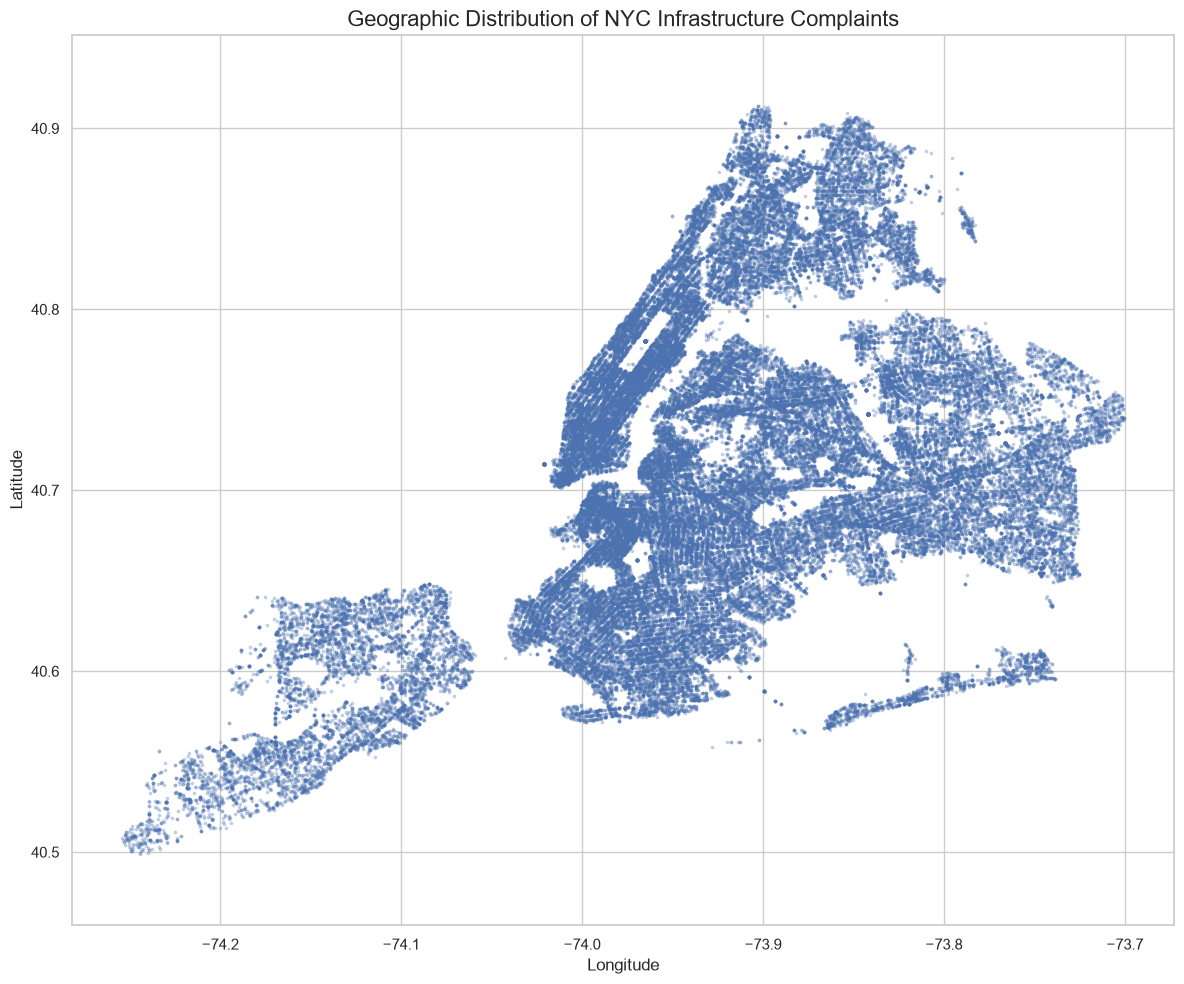

In [63]:
plt.figure(figsize=(12, 10))

plt.scatter(
    geo_valid["longitude"],
    geo_valid["latitude"],
    s=3,
    alpha=0.25
)

plt.title(
    "Geographic Distribution of NYC Infrastructure Complaints",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.axis("equal")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "geographic_complaint_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Borough-wise geographic distribution

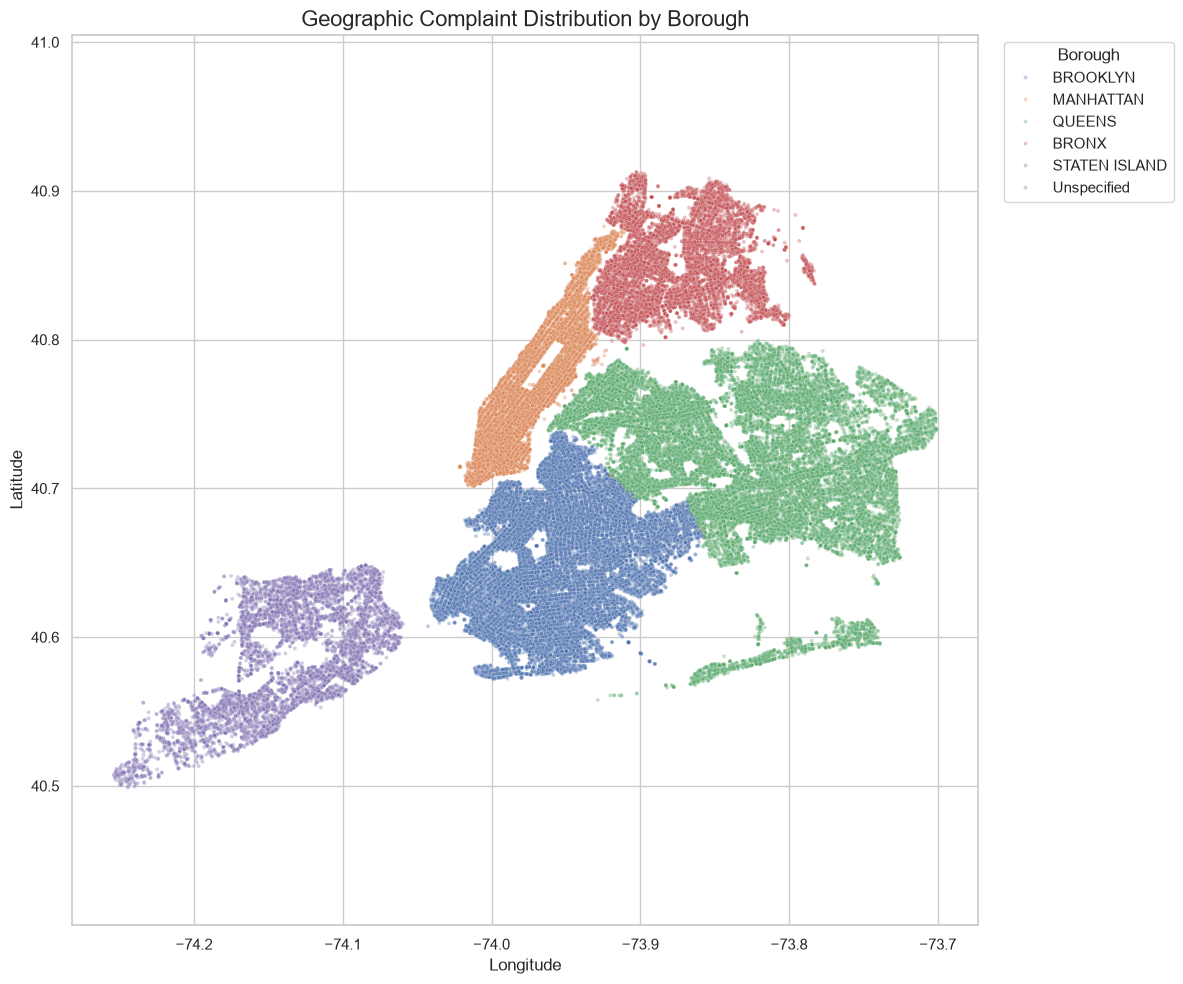

In [64]:
plt.figure(figsize=(12, 10))

sns.scatterplot(
    data=geo_valid,
    x="longitude",
    y="latitude",
    hue="borough",
    alpha=0.35,
    s=8
)

plt.title(
    "Geographic Complaint Distribution by Borough",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    title="Borough",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.axis("equal")
plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "geographic_distribution_by_borough.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Spatial Density Analysis

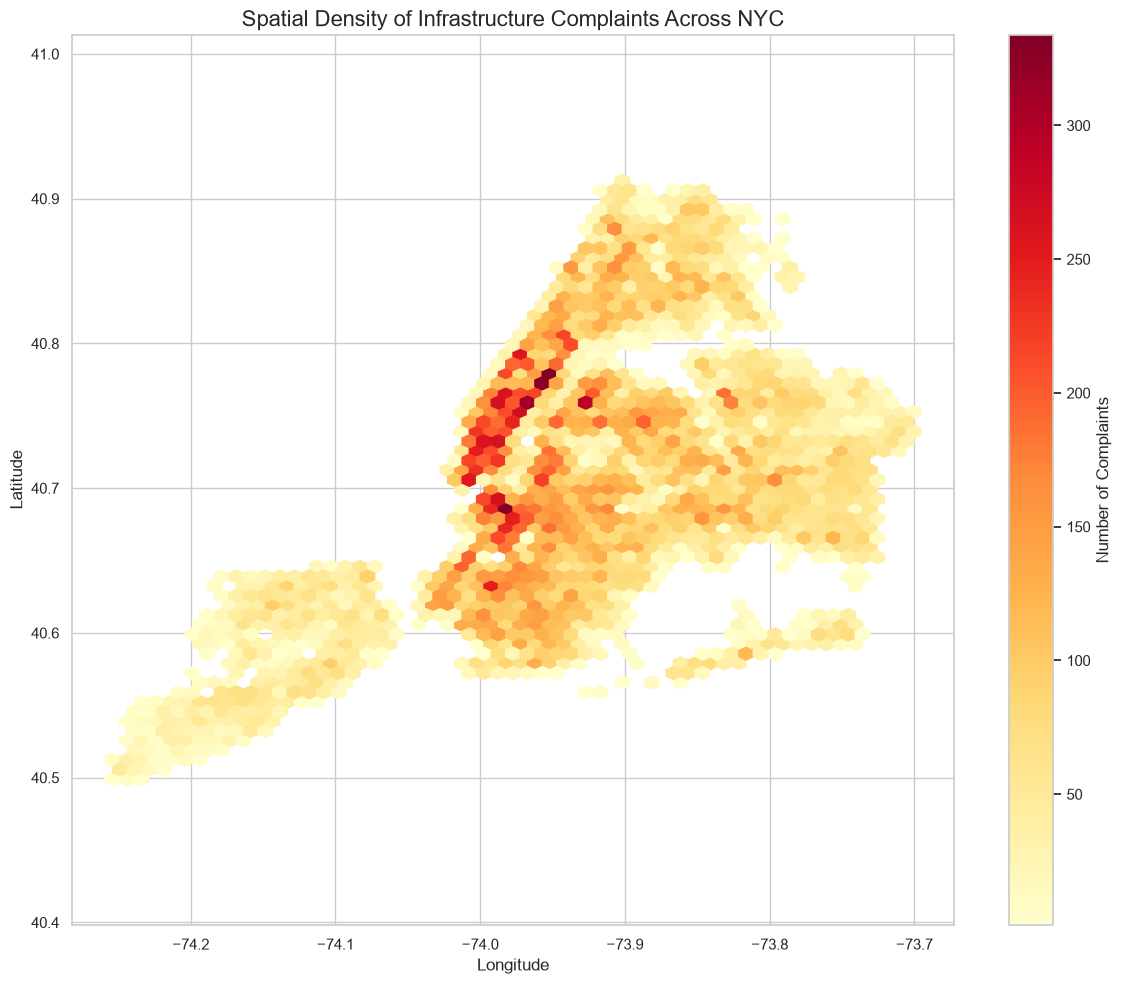

In [65]:
plt.figure(figsize=(12, 10))

density = plt.hexbin(
    geo_valid["longitude"],
    geo_valid["latitude"],
    gridsize=55,
    mincnt=1,
    cmap="YlOrRd"
)

plt.colorbar(
    density,
    label="Number of Complaints"
)

plt.title(
    "Spatial Density of Infrastructure Complaints Across NYC",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.axis("equal")
plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "spatial_complaint_density.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [66]:
top_categories = (
    df["complaint_type"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

print("Selected categories:")

for category in top_categories:
    print("-", category)

Selected categories:
- Street Condition
- Traffic Signal Condition
- Street Light Condition
- Sewer
- Sidewalk Condition


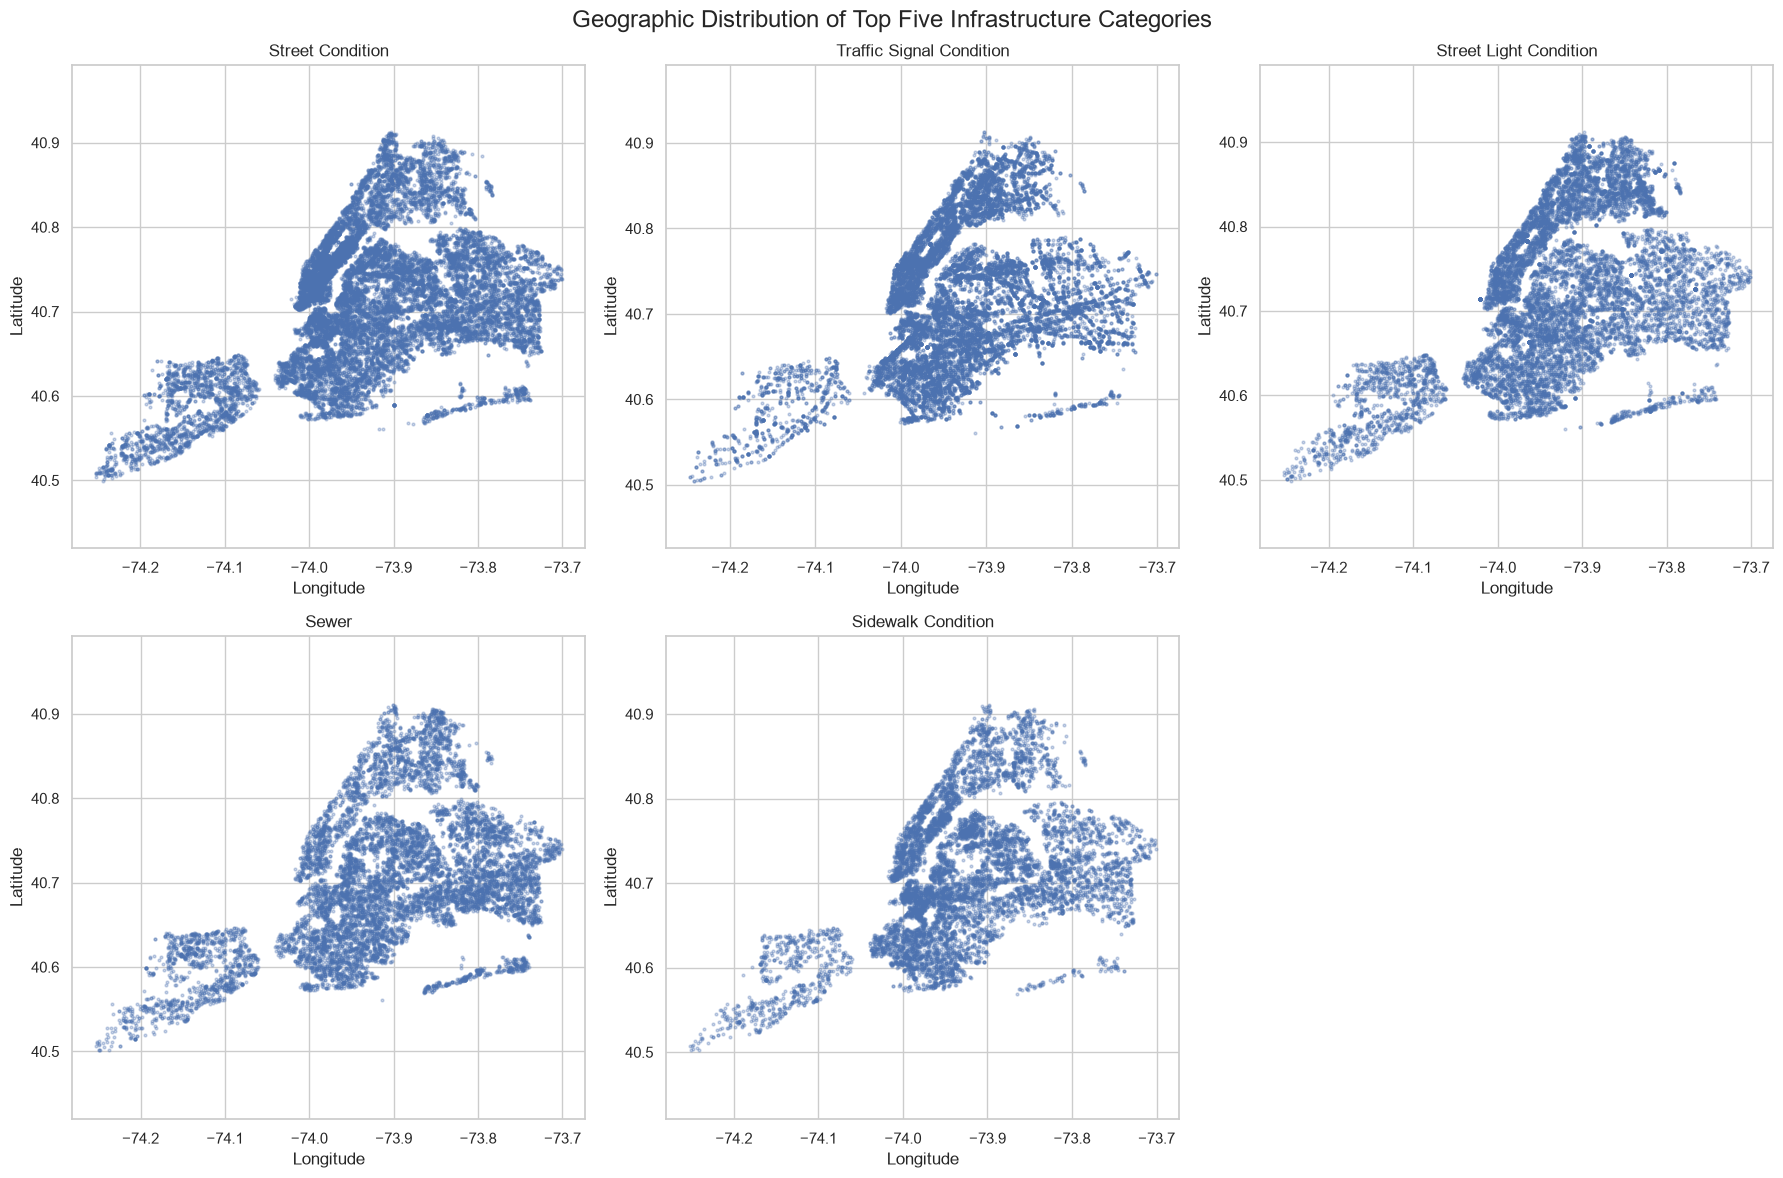

In [67]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 12)
)

axes = axes.flatten()

for index, category in enumerate(top_categories):

    category_data = geo_valid[
        geo_valid["complaint_type"] == category
    ]

    axes[index].scatter(
        category_data["longitude"],
        category_data["latitude"],
        s=4,
        alpha=0.3
    )

    axes[index].set_title(category)

    axes[index].set_xlabel("Longitude")
    axes[index].set_ylabel("Latitude")

    axes[index].set_aspect("equal", adjustable="datalim")


# Remove unused subplot
fig.delaxes(axes[5])

fig.suptitle(
    "Geographic Distribution of Top Five Infrastructure Categories",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "top_categories_geographic_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Geographic Coverage by Borough

In [68]:
borough_coordinate_summary = (
    geo_df.groupby("borough")
    .agg(
        total_records=("unique_key", "count"),
        records_with_coordinates=("has_coordinates", "sum")
    )
)

borough_coordinate_summary["coordinate_percentage"] = (
    borough_coordinate_summary["records_with_coordinates"]
    / borough_coordinate_summary["total_records"]
    * 100
).round(2)

borough_coordinate_summary = (
    borough_coordinate_summary.reset_index()
)

display(borough_coordinate_summary)

,borough,total_records,records_with_coordinates,coordinate_percentage
0,BRONX,12550,11153,88.87
1,BROOKLYN,30468,28110,92.26
2,MANHATTAN,15558,13990,89.92
3,QUEENS,32805,28431,86.67
4,STATEN ISLAND,8360,7516,89.90
5,Unspecified,259,44,16.99


In [69]:
borough_coordinate_summary.to_csv(
    EDA_TABLES_DIR / "coordinate_availability_by_borough.csv",
    index=False
)

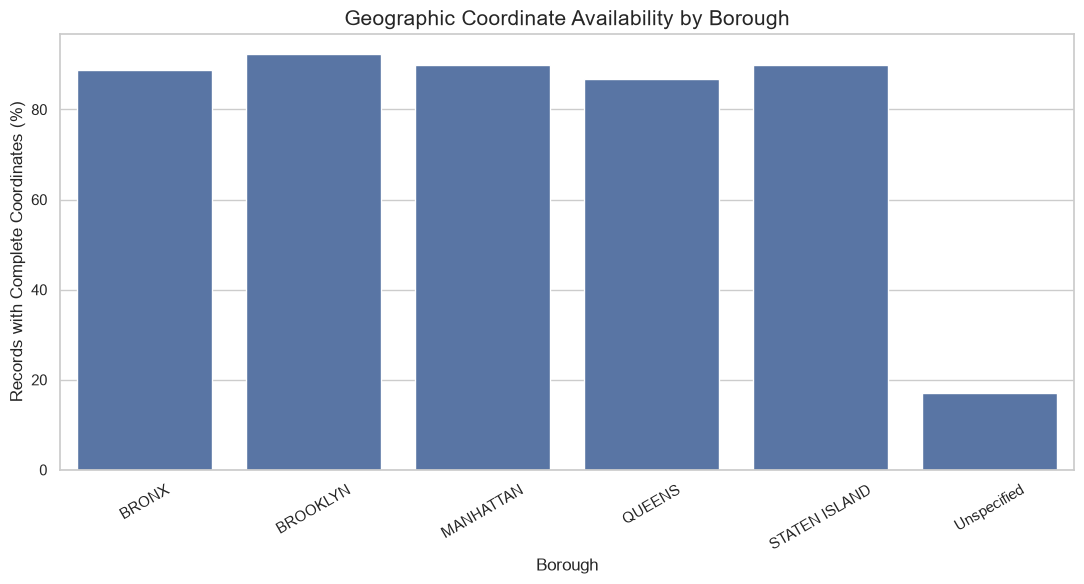

In [70]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=borough_coordinate_summary,
    x="borough",
    y="coordinate_percentage"
)

plt.title(
    "Geographic Coordinate Availability by Borough",
    fontsize=15
)

plt.xlabel("Borough")
plt.ylabel("Records with Complete Coordinates (%)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "coordinate_availability_by_borough.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

89.24% of the dataset has complete geographic coordinates.
Geographic coverage differs across boroughs.
Complaint locations show spatial concentration rather than uniform distribution.
Different infrastructure categories have potentially different geographic patterns.
Geographic aggregation will be necessary before applying K-Means.

### Section 6 — Resolution-Time Analysis

Prepare resolution-time data

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config.config import (
    EDA_FIGURES_DIR,
    EDA_TABLES_DIR,
    REPORTS_DIR
)

sns.set_theme(style="whitegrid")

print("Resolution-time analysis initialized.")

Resolution-time analysis initialized.


In [72]:
required_columns = [
    "created_date",
    "closed_date",
    "resolution_hours",
    "complaint_type",
    "borough",
    "status"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


In [73]:
resolution_df = df.copy()

# Convert date columns
resolution_df["created_date"] = pd.to_datetime(
    resolution_df["created_date"],
    errors="coerce"
)

resolution_df["closed_date"] = pd.to_datetime(
    resolution_df["closed_date"],
    errors="coerce"
)

# Convert resolution time to numeric
resolution_df["resolution_hours"] = pd.to_numeric(
    resolution_df["resolution_hours"],
    errors="coerce"
)

# Identify records with valid resolution times
resolution_df["valid_resolution"] = (
    resolution_df["resolution_hours"].notna()
    & (resolution_df["resolution_hours"] >= 0)
)

print("Total records:", len(resolution_df))

print(
    "Valid resolution records:",
    resolution_df["valid_resolution"].sum()
)

print(
    "Missing or invalid resolution records:",
    (~resolution_df["valid_resolution"]).sum()
)

Total records: 100000
Valid resolution records: 96532
Missing or invalid resolution records: 3468


In [74]:
valid_resolution_df = resolution_df[
    resolution_df["valid_resolution"]
].copy()

resolution_statistics = (
    valid_resolution_df["resolution_hours"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame(name="resolution_hours")
)

resolution_statistics["resolution_days"] = (
    resolution_statistics["resolution_hours"] / 24
)

display(resolution_statistics.round(2))

,resolution_hours,resolution_days
count,96532.00,4022.17
mean,398.53,16.61
std,1528.74,63.70
min,0.00,0.00
25%,4.85,0.20
50%,35.90,1.50
75%,170.32,7.10
90%,525.63,21.90
95%,1868.81,77.87
99%,7533.91,313.91


In [75]:
resolution_statistics.to_csv(
    EDA_TABLES_DIR / "resolution_time_statistics.csv"
)

In [76]:
resolution_skewness = (
    valid_resolution_df["resolution_hours"].skew()
)

print("Resolution-time skewness:", round(resolution_skewness, 3))

if resolution_skewness > 1:
    print("Interpretation: Strong positive skewness.")

elif resolution_skewness > 0:
    print("Interpretation: Positive skewness.")

else:
    print("Interpretation: Symmetric or negatively skewed distribution.")

Resolution-time skewness: 7.753
Interpretation: Strong positive skewness.


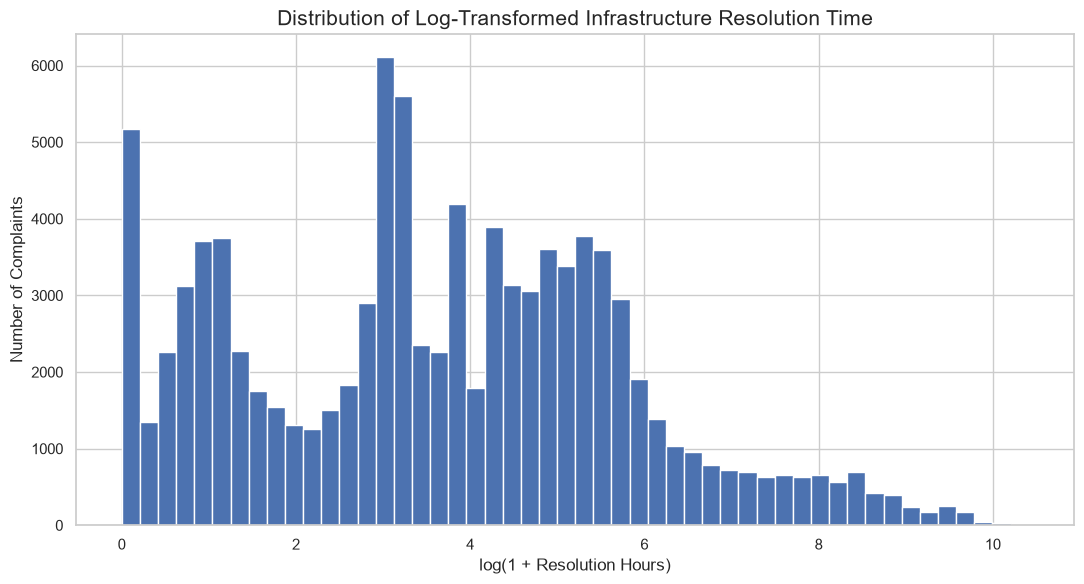

In [77]:
plt.figure(figsize=(11, 6))

plt.hist(
    np.log1p(valid_resolution_df["resolution_hours"]),
    bins=50
)

plt.title(
    "Distribution of Log-Transformed Infrastructure Resolution Time",
    fontsize=15
)

plt.xlabel("log(1 + Resolution Hours)")
plt.ylabel("Number of Complaints")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

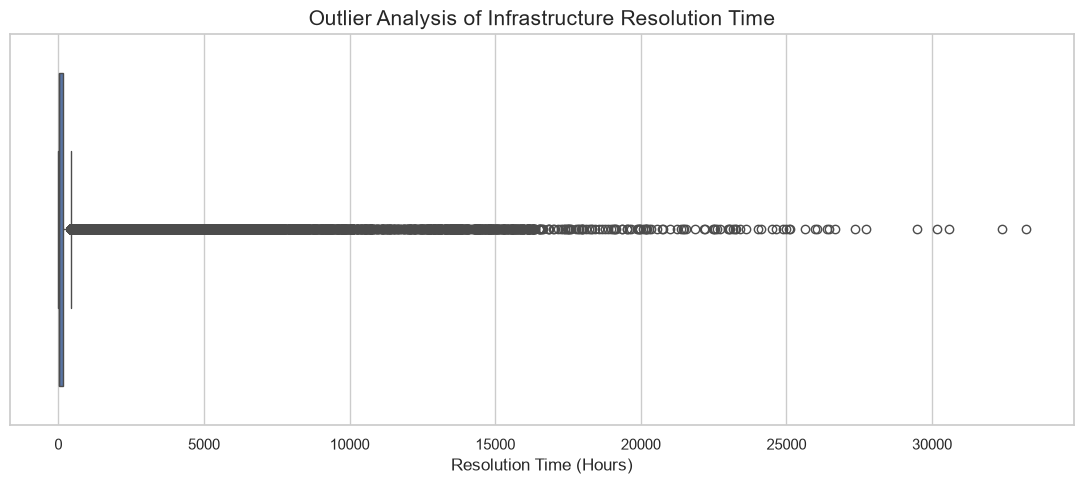

In [78]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    x=valid_resolution_df["resolution_hours"]
)

plt.title(
    "Outlier Analysis of Infrastructure Resolution Time",
    fontsize=15
)

plt.xlabel("Resolution Time (Hours)")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Resolution Time by Infrastructure Category

In [79]:
category_resolution = (
    valid_resolution_df
    .groupby("complaint_type")
    .agg(
        complaint_count=("resolution_hours", "count"),
        mean_resolution_hours=("resolution_hours", "mean"),
        median_resolution_hours=("resolution_hours", "median"),
        p90_resolution_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

category_resolution = category_resolution.sort_values(
    "median_resolution_hours",
    ascending=False
)

display(category_resolution)

,complaint_type,complaint_count,mean_resolution_hours,median_resolution_hours,p90_resolution_hours
2,Root/Sewer/Sidewalk Condition,3842,3426.30,2210.22,7601.96
12,Water Drainage,12,460.56,465.41,751.11
1,Curb Condition,3097,591.11,312.74,1324.78
0,Bridge Condition,123,1090.01,220.84,3712.38
5,Sidewalk Condition,10771,293.49,194.30,507.36
13,Water Leak,320,245.64,159.13,509.03
7,Street Light Condition,13189,863.97,141.45,2007.15
10,Street Sign - Missing,1521,776.02,122.24,3260.55
9,Street Sign - Dangling,1541,269.01,122.04,313.21
8,Street Sign - Damaged,2186,595.26,116.68,2244.32


In [80]:
category_resolution.to_csv(
    EDA_TABLES_DIR / "category_resolution_statistics.csv",
    index=False
)

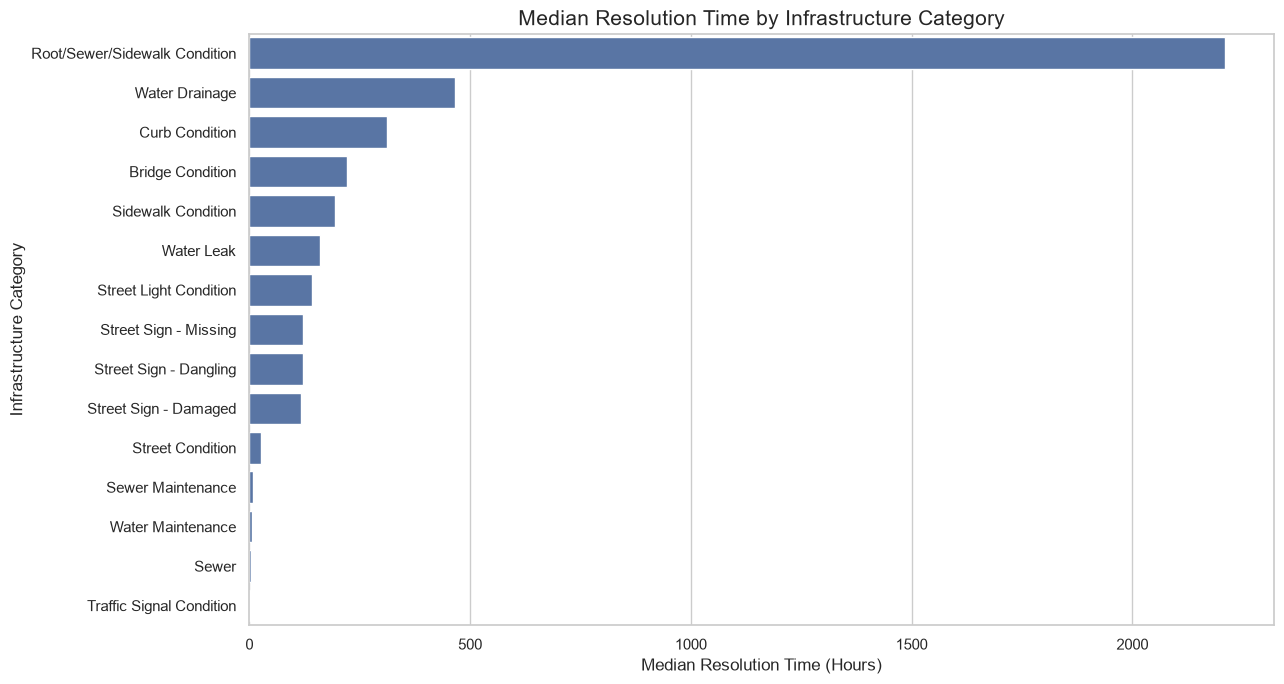

In [81]:
plt.figure(figsize=(13, 7))

sns.barplot(
    data=category_resolution,
    x="median_resolution_hours",
    y="complaint_type"
)

plt.title(
    "Median Resolution Time by Infrastructure Category",
    fontsize=15
)

plt.xlabel("Median Resolution Time (Hours)")
plt.ylabel("Infrastructure Category")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Resolution Time by Borough

In [82]:
borough_resolution = (
    valid_resolution_df
    .groupby("borough")
    .agg(
        complaint_count=("resolution_hours", "count"),
        mean_resolution_hours=("resolution_hours", "mean"),
        median_resolution_hours=("resolution_hours", "median"),
        p90_resolution_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

borough_resolution = borough_resolution.sort_values(
    "median_resolution_hours",
    ascending=False
)

display(borough_resolution)

,borough,complaint_count,mean_resolution_hours,median_resolution_hours,p90_resolution_hours
0,BRONX,12037,375.45,46.24,492.45
1,BROOKLYN,29645,378.35,39.36,550.01
3,QUEENS,31441,446.67,39.23,642.65
4,STATEN ISLAND,8105,531.54,38.12,692.77
2,MANHATTAN,15052,283.86,23.70,331.70
5,Unspecified,252,440.49,19.61,1219.57


In [83]:
borough_resolution.to_csv(
    EDA_TABLES_DIR / "borough_resolution_statistics.csv",
    index=False
)

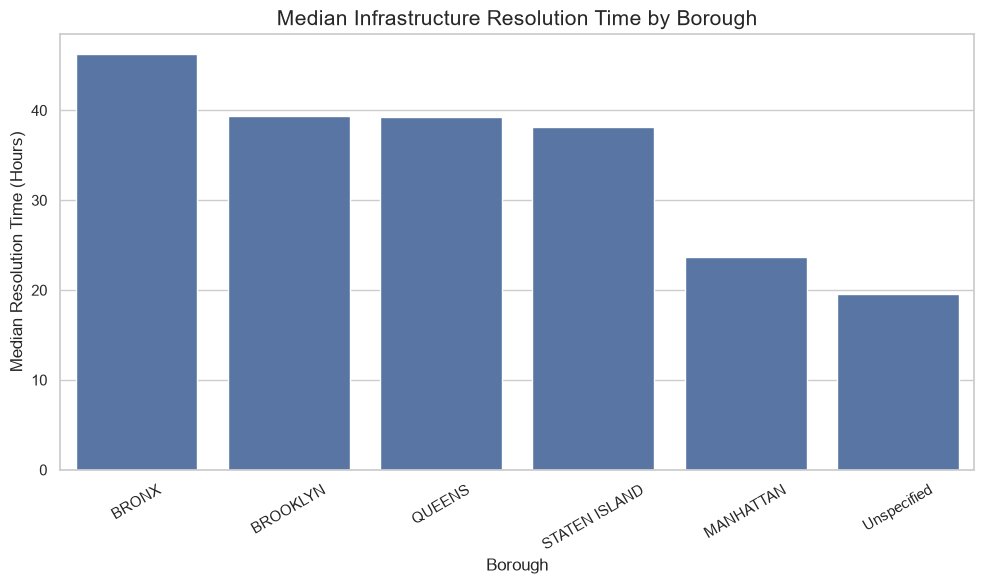

In [84]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=borough_resolution,
    x="borough",
    y="median_resolution_hours"
)

plt.title(
    "Median Infrastructure Resolution Time by Borough",
    fontsize=15
)

plt.xlabel("Borough")
plt.ylabel("Median Resolution Time (Hours)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "resolution_time_by_borough.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Open and Closed Complaint Analysis

In [85]:
status_summary = (
    resolution_df["status"]
    .fillna("Missing")
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "status",
    "complaint_count"
]

status_summary["percentage"] = (
    status_summary["complaint_count"]
    / len(resolution_df) * 100
).round(2)

display(status_summary)

,status,complaint_count,percentage
0,Closed,96374,96.37
1,Pending,1933,1.93
2,In Progress,707,0.71
3,Assigned,640,0.64
4,Open,220,0.22
5,Started,122,0.12
6,Unspecified,4,0.00


In [86]:
status_summary.to_csv(
    EDA_TABLES_DIR / "complaint_status_summary.csv",
    index=False
)

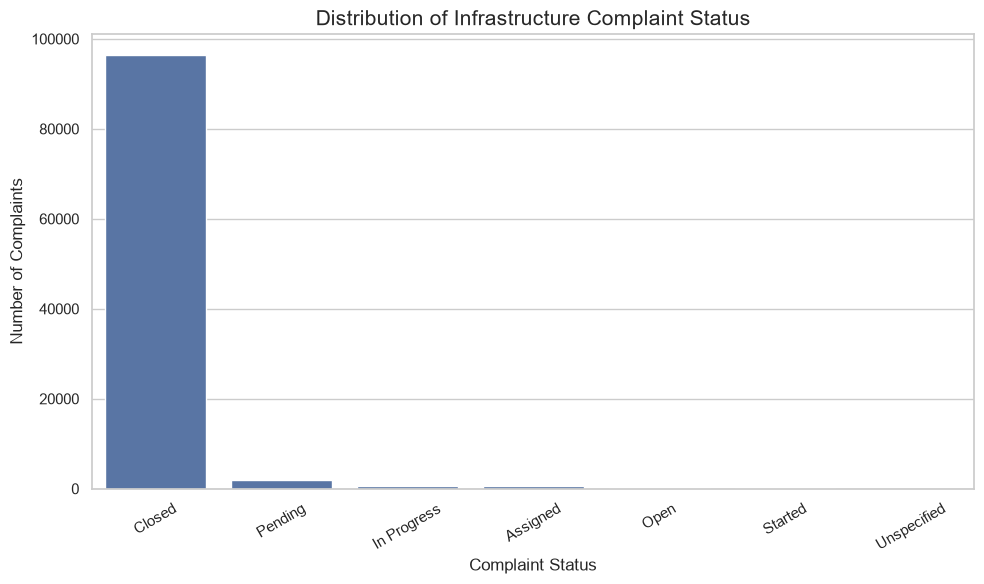

In [87]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=status_summary,
    x="status",
    y="complaint_count"
)

plt.title(
    "Distribution of Infrastructure Complaint Status",
    fontsize=15
)

plt.xlabel("Complaint Status")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "complaint_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Temporal Resolution Analysis

In [88]:
temporal_resolution_df = valid_resolution_df.copy()

temporal_resolution_df["year_month"] = (
    temporal_resolution_df["created_date"]
    .dt.to_period("M")
)

monthly_resolution = (
    temporal_resolution_df
    .groupby("year_month")
    .agg(
        complaint_count=("resolution_hours", "count"),
        median_resolution_hours=("resolution_hours", "median")
    )
    .reset_index()
)

monthly_resolution["year_month"] = (
    monthly_resolution["year_month"].astype(str)
)

display(monthly_resolution.head())

,year_month,complaint_count,median_resolution_hours
0,2023-01,2866,22.50
1,2023-02,2488,21.48
2,2023-03,3040,22.24
3,2023-04,2501,22.52
4,2023-05,2567,37.85


In [89]:
monthly_resolution.to_csv(
    EDA_TABLES_DIR / "monthly_resolution_trends.csv",
    index=False
)

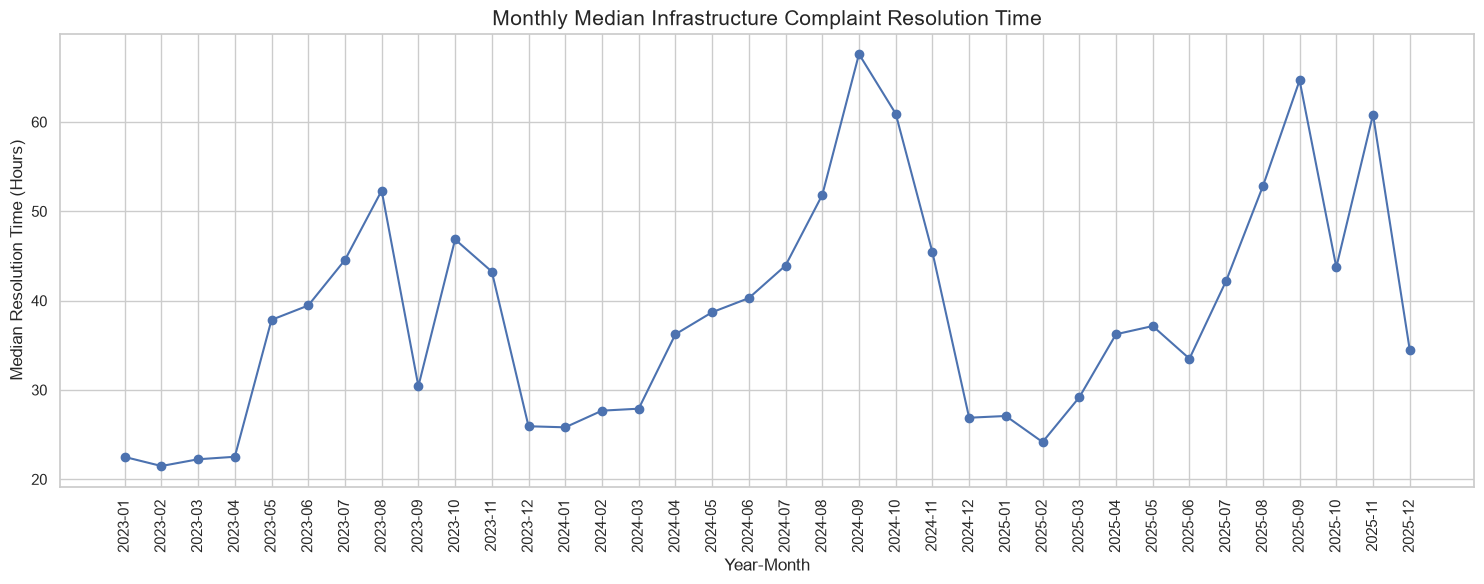

In [90]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_resolution["year_month"],
    monthly_resolution["median_resolution_hours"],
    marker="o"
)

plt.title(
    "Monthly Median Infrastructure Complaint Resolution Time",
    fontsize=15
)

plt.xlabel("Year-Month")
plt.ylabel("Median Resolution Time (Hours)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    EDA_FIGURES_DIR / "monthly_resolution_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identify suspicious records

In [91]:
resolution_audit = resolution_df.copy()

resolution_audit["resolution_days"] = (
    resolution_audit["resolution_hours"] / 24
)

# Check timestamp consistency
resolution_audit["closed_before_created"] = (
    resolution_audit["closed_date"]
    < resolution_audit["created_date"]
)

# Classify resolution times
resolution_audit["resolution_flag"] = np.select(
    [
        resolution_audit["resolution_hours"].isna(),
        resolution_audit["resolution_hours"] < 0,
        resolution_audit["resolution_hours"] > 365 * 24,
        resolution_audit["resolution_hours"] > 180 * 24,
        resolution_audit["resolution_hours"] > 90 * 24
    ],
    [
        "Missing",
        "Negative",
        "Above 365 days",
        "Above 180 days",
        "Above 90 days"
    ],
    default="Normal"
)

print(
    resolution_audit["resolution_flag"]
    .value_counts()
)

resolution_flag
Normal            92128
Missing            3468
Above 90 days      2228
Above 180 days     1394
Above 365 days      782
Name: count, dtype: int64


Inspect extreme complaints

In [92]:
extreme_complaints = (
    resolution_audit[
        resolution_audit["resolution_hours"] > 90 * 24
    ]
    [
        [
            "created_date",
            "closed_date",
            "complaint_type",
            "borough",
            "resolution_hours",
            "resolution_days"
        ]
    ]
    .sort_values(
        "resolution_hours",
        ascending=False
    )
)

display(extreme_complaints.head(20))

,created_date,closed_date,complaint_type,borough,resolution_hours,resolution_days
336,2023-01-04 16:34:35,2026-10-19 12:35:32,Street Condition,BROOKLYN,33212.02,1383.83
1001,2023-01-11 17:15:00,2026-09-22 16:48:00,Street Light Condition,BROOKLYN,32399.55,1349.98
9009,2023-04-04 13:36:50,2026-09-30 00:20:00,Sewer Maintenance,QUEENS,30586.72,1274.45
5895,2023-03-03 09:40:06,2026-08-11 01:40:00,Sewer Maintenance,QUEENS,30160.00,1256.67
3870,2023-02-09 17:02:00,2026-06-22 12:42:00,Street Light Condition,QUEENS,29491.67,1228.82
5721,2023-03-01 14:51:00,2026-04-30 15:59:00,Street Light Condition,BROOKLYN,27745.13,1156.05
11225,2023-04-29 20:28:00,2026-06-12 12:55:00,Street Light Condition,QUEENS,27352.45,1139.69
21776,2023-09-01 22:06:29,2026-09-17 07:27:37,Root/Sewer/Sidewalk Condition,STATEN ISLAND,26673.35,1111.39
18301,2023-07-24 07:45:00,2026-07-30 17:41:00,Street Light Condition,MANHATTAN,26457.93,1102.41
16138,2023-06-27 15:12:00,2026-07-01 11:15:00,Street Light Condition,BRONX,26396.05,1099.84


Inspect category-level reliability

In [93]:
category_reliability = (
    resolution_audit[
        resolution_audit["valid_resolution"]
    ]
    .groupby("complaint_type")
    .agg(
        valid_records=("resolution_hours", "count"),
        median_hours=("resolution_hours", "median"),
        p90_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        ),
        maximum_hours=("resolution_hours", "max")
    )
    .reset_index()
)

display(
    category_reliability.sort_values(
        "valid_records",
        ascending=False
    )
)

,complaint_type,valid_records,median_hours,p90_hours,maximum_hours
6,Street Condition,28906,26.42,148.63,33212.02
11,Traffic Signal Condition,18893,2.22,44.15,20725.98
7,Street Light Condition,13189,141.45,2007.15,32399.55
3,Sewer,11642,4.38,103.54,23045.97
5,Sidewalk Condition,10771,194.30,507.36,16340.12
2,Root/Sewer/Sidewalk Condition,3842,2210.22,7601.96,26673.35
1,Curb Condition,3097,312.74,1324.78,10820.12
8,Street Sign - Damaged,2186,116.68,2244.32,11169.81
9,Street Sign - Dangling,1541,122.04,313.21,12833.84
10,Street Sign - Missing,1521,122.24,3260.55,12928.21


Save the audit

In [94]:
category_reliability.to_csv(
    EDA_TABLES_DIR / "resolution_time_reliability.csv",
    index=False
)

extreme_complaints.to_csv(
    EDA_TABLES_DIR / "extreme_resolution_complaints.csv",
    index=False
)

print("Resolution-time audit completed.")

Resolution-time audit completed.


### Phase 7 — Repeated Complaint Analysis

In [95]:
import pandas as pd
import numpy as np

required_columns = [
    "complaint_type",
    "borough",
    "latitude",
    "longitude",
    "created_date"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

repeat_df = df[required_columns].copy()

repeat_df["created_date"] = pd.to_datetime(
    repeat_df["created_date"],
    errors="coerce"
)

repeat_df["latitude"] = pd.to_numeric(
    repeat_df["latitude"],
    errors="coerce"
)

repeat_df["longitude"] = pd.to_numeric(
    repeat_df["longitude"],
    errors="coerce"
)

repeat_df = repeat_df.dropna(
    subset=required_columns
)

print("Valid records:", len(repeat_df))
print("Unique complaint categories:",
      repeat_df["complaint_type"].nunique())
print("Unique boroughs:",
      repeat_df["borough"].nunique())

Valid records: 89244
Unique complaint categories: 15
Unique boroughs: 6


In [96]:
repeat_df["latitude_rounded"] = (
    repeat_df["latitude"].round(4)
)

repeat_df["longitude_rounded"] = (
    repeat_df["longitude"].round(4)
)

location_columns = [
    "complaint_type",
    "borough",
    "latitude_rounded",
    "longitude_rounded"
]

print(repeat_df.head())

             complaint_type    borough  latitude  longitude  \
0  Traffic Signal Condition   BROOKLYN     40.67     -73.88   
1    Street Light Condition   BROOKLYN     40.68     -73.97   
2  Traffic Signal Condition  MANHATTAN     40.73     -73.99   
4     Street Sign - Damaged   BROOKLYN     40.66     -73.88   
5  Traffic Signal Condition     QUEENS     40.69     -73.86   

         created_date  latitude_rounded  longitude_rounded  
0 2023-01-01 02:51:00             40.67             -73.88  
1 2023-01-01 03:33:00             40.68             -73.97  
2 2023-01-01 07:53:00             40.73             -73.99  
4 2023-01-01 10:29:31             40.66             -73.88  
5 2023-01-01 10:31:00             40.69             -73.86  


In [97]:
repeated_locations = (
    repeat_df
    .groupby(location_columns)
    .agg(
        complaint_count=("created_date", "count"),
        first_reported=("created_date", "min"),
        last_reported=("created_date", "max"),
        unique_report_dates=("created_date", "nunique")
    )
    .reset_index()
)

repeated_locations = repeated_locations.sort_values(
    "complaint_count",
    ascending=False
)

print("Total location-category groups:",
      len(repeated_locations))

print(
    "Repeated location-category groups:",
    (repeated_locations["complaint_count"] > 1).sum()
)

display(repeated_locations.head(20))

Total location-category groups: 67432
Repeated location-category groups: 12188


,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates
49625,Street Light Condition,MANHATTAN,40.78,-73.97,80,2023-01-10 20:47:00,2025-12-23 11:01:00,80
52074,Street Light Condition,QUEENS,40.74,-73.84,66,2023-02-01 12:41:00,2025-09-04 10:37:00,66
58542,Street Sign - Missing,QUEENS,40.73,-73.81,42,2023-03-23 16:42:36,2024-09-30 12:04:56,42
48818,Street Light Condition,MANHATTAN,40.71,-74.02,40,2023-03-16 09:05:00,2025-12-31 11:58:00,40
47615,Street Light Condition,BROOKLYN,40.66,-73.96,35,2023-01-09 14:02:00,2025-11-15 23:45:00,35
66321,Traffic Signal Condition,QUEENS,40.77,-73.92,28,2023-01-06 14:29:00,2025-07-16 02:10:00,28
64902,Traffic Signal Condition,QUEENS,40.69,-73.85,27,2023-01-03 11:45:00,2025-12-31 13:46:00,27
51698,Street Light Condition,QUEENS,40.73,-73.77,24,2023-04-03 10:06:00,2025-12-03 15:22:00,22
63846,Traffic Signal Condition,MANHATTAN,40.78,-73.97,24,2023-01-26 11:18:00,2025-11-09 13:39:00,24
64608,Traffic Signal Condition,QUEENS,40.67,-73.78,22,2023-01-20 14:55:00,2025-12-06 10:10:00,22


In [98]:
total_groups = len(repeated_locations)

repeated_groups = (
    repeated_locations["complaint_count"] > 1
).sum()

repeat_percentage = (
    repeated_groups / total_groups * 100
    if total_groups > 0 else 0
)

print("Total location-category groups:", total_groups)
print("Repeated groups:", repeated_groups)

print(
    f"Repeated location percentage: "
    f"{repeat_percentage:.2f}%"
)

Total location-category groups: 67432
Repeated groups: 12188
Repeated location percentage: 18.07%


In [99]:
category_repeats = (
    repeated_locations
    .groupby("complaint_type")
    .agg(
        total_locations=("complaint_count", "count"),
        repeated_locations=(
            "complaint_count",
            lambda x: (x > 1).sum()
        ),
        total_complaints=("complaint_count", "sum"),
        average_complaints=("complaint_count", "mean"),
        maximum_complaints=("complaint_count", "max")
    )
    .reset_index()
)

category_repeats["repeat_rate_percentage"] = (
    category_repeats["repeated_locations"]
    / category_repeats["total_locations"]
    * 100
)

category_repeats = category_repeats.sort_values(
    "repeat_rate_percentage",
    ascending=False
)

display(category_repeats)

,complaint_type,total_locations,repeated_locations,total_complaints,average_complaints,maximum_complaints,repeat_rate_percentage
11,Traffic Signal Condition,8060,4082,17638,2.19,28,50.65
7,Street Light Condition,9748,2359,13671,1.40,80,24.20
6,Street Condition,16990,2945,21689,1.28,15,17.33
3,Sewer,10368,1166,11883,1.15,10,11.25
5,Sidewalk Condition,9465,936,10720,1.13,11,9.89
2,Root/Sewer/Sidewalk Condition,4052,319,4403,1.09,4,7.87
13,Water Leak,419,26,448,1.07,4,6.21
1,Curb Condition,2899,164,3096,1.07,9,5.66
4,Sewer Maintenance,404,17,421,1.04,2,4.21
10,Street Sign - Missing,1374,56,1496,1.09,42,4.08


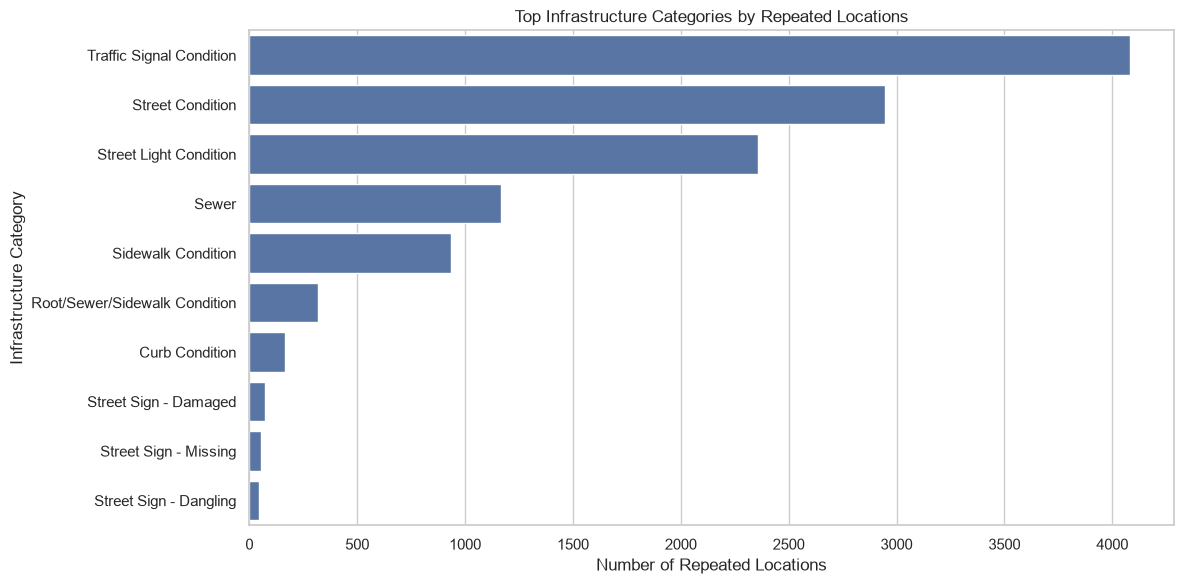

In [100]:
top_categories = (
    category_repeats
    .sort_values(
        "repeated_locations",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="repeated_locations",
    y="complaint_type"
)

plt.title("Top Infrastructure Categories by Repeated Locations")
plt.xlabel("Number of Repeated Locations")
plt.ylabel("Infrastructure Category")

plt.tight_layout()
plt.show()

In [101]:
high_recurrence_locations = (
    repeated_locations[
        repeated_locations["complaint_count"] >= 5
    ]
    .copy()
)

high_recurrence_locations = (
    high_recurrence_locations.sort_values(
        "complaint_count",
        ascending=False
    )
)

print(
    "Locations with at least 5 complaints:",
    len(high_recurrence_locations)
)

display(high_recurrence_locations.head(25))

Locations with at least 5 complaints: 1086


,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates
49625,Street Light Condition,MANHATTAN,40.78,-73.97,80,2023-01-10 20:47:00,2025-12-23 11:01:00,80
52074,Street Light Condition,QUEENS,40.74,-73.84,66,2023-02-01 12:41:00,2025-09-04 10:37:00,66
58542,Street Sign - Missing,QUEENS,40.73,-73.81,42,2023-03-23 16:42:36,2024-09-30 12:04:56,42
48818,Street Light Condition,MANHATTAN,40.71,-74.02,40,2023-03-16 09:05:00,2025-12-31 11:58:00,40
47615,Street Light Condition,BROOKLYN,40.66,-73.96,35,2023-01-09 14:02:00,2025-11-15 23:45:00,35
66321,Traffic Signal Condition,QUEENS,40.77,-73.92,28,2023-01-06 14:29:00,2025-07-16 02:10:00,28
64902,Traffic Signal Condition,QUEENS,40.69,-73.85,27,2023-01-03 11:45:00,2025-12-31 13:46:00,27
51698,Street Light Condition,QUEENS,40.73,-73.77,24,2023-04-03 10:06:00,2025-12-03 15:22:00,22
63846,Traffic Signal Condition,MANHATTAN,40.78,-73.97,24,2023-01-26 11:18:00,2025-11-09 13:39:00,24
64608,Traffic Signal Condition,QUEENS,40.67,-73.78,22,2023-01-20 14:55:00,2025-12-06 10:10:00,22


In [102]:
repeated_locations.to_csv(
    EDA_TABLES_DIR / "repeated_complaint_locations.csv",
    index=False
)

category_repeats.to_csv(
    EDA_TABLES_DIR / "category_repeat_statistics.csv",
    index=False
)

high_recurrence_locations.to_csv(
    EDA_TABLES_DIR / "high_recurrence_locations.csv",
    index=False
)

print("Repeated complaint analysis completed.")

Repeated complaint analysis completed.


In [103]:
repeated_locations["recurrence_days"] = (
    repeated_locations["last_reported"]
    - repeated_locations["first_reported"]
).dt.days

repeated_locations["recurrence_months"] = (
    repeated_locations["recurrence_days"] / 30.44
)

display(
    repeated_locations.sort_values(
        "recurrence_days",
        ascending=False
    ).head(20)
)

,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates,recurrence_days,recurrence_months
64902,Traffic Signal Condition,QUEENS,40.69,-73.85,27,2023-01-03 11:45:00,2025-12-31 13:46:00,27,1093,35.91
65034,Traffic Signal Condition,QUEENS,40.70,-73.88,3,2023-01-05 14:40:00,2025-12-31 19:07:00,3,1091,35.84
63552,Traffic Signal Condition,MANHATTAN,40.76,-73.98,4,2023-01-03 13:44:00,2025-12-27 11:01:00,4,1088,35.74
39912,Street Condition,QUEENS,40.73,-73.76,5,2023-01-03 10:39:05,2025-12-22 15:30:13,5,1084,35.61
44632,Street Light Condition,BRONX,40.83,-73.91,2,2023-01-06 14:09:00,2025-12-22 18:20:00,2,1081,35.51
49625,Street Light Condition,MANHATTAN,40.78,-73.97,80,2023-01-10 20:47:00,2025-12-23 11:01:00,80,1077,35.38
61409,Traffic Signal Condition,BROOKLYN,40.65,-73.91,9,2023-01-03 00:50:00,2025-12-14 11:46:00,9,1076,35.35
63648,Traffic Signal Condition,MANHATTAN,40.77,-73.98,2,2023-01-10 23:08:00,2025-12-21 15:57:00,2,1075,35.32
61825,Traffic Signal Condition,BROOKLYN,40.67,-73.99,9,2023-01-20 13:34:00,2025-12-30 19:48:00,9,1075,35.32
50468,Street Light Condition,QUEENS,40.60,-73.78,5,2023-01-05 15:42:00,2025-12-16 10:34:00,5,1075,35.32


In [104]:
persistent_locations = repeated_locations[
    (repeated_locations["complaint_count"] >= 5) &
    (repeated_locations["recurrence_days"] >= 90)
].copy()

print(
    "Persistent complaint locations:",
    len(persistent_locations)
)

display(
    persistent_locations.sort_values(
        "complaint_count",
        ascending=False
    ).head(20)
)

Persistent complaint locations: 1030


,complaint_type,borough,latitude_rounded,longitude_rounded,complaint_count,first_reported,last_reported,unique_report_dates,recurrence_days,recurrence_months
49625,Street Light Condition,MANHATTAN,40.78,-73.97,80,2023-01-10 20:47:00,2025-12-23 11:01:00,80,1077,35.38
52074,Street Light Condition,QUEENS,40.74,-73.84,66,2023-02-01 12:41:00,2025-09-04 10:37:00,66,945,31.04
58542,Street Sign - Missing,QUEENS,40.73,-73.81,42,2023-03-23 16:42:36,2024-09-30 12:04:56,42,556,18.27
48818,Street Light Condition,MANHATTAN,40.71,-74.02,40,2023-03-16 09:05:00,2025-12-31 11:58:00,40,1021,33.54
47615,Street Light Condition,BROOKLYN,40.66,-73.96,35,2023-01-09 14:02:00,2025-11-15 23:45:00,35,1041,34.20
66321,Traffic Signal Condition,QUEENS,40.77,-73.92,28,2023-01-06 14:29:00,2025-07-16 02:10:00,28,921,30.26
64902,Traffic Signal Condition,QUEENS,40.69,-73.85,27,2023-01-03 11:45:00,2025-12-31 13:46:00,27,1093,35.91
51698,Street Light Condition,QUEENS,40.73,-73.77,24,2023-04-03 10:06:00,2025-12-03 15:22:00,22,975,32.03
63846,Traffic Signal Condition,MANHATTAN,40.78,-73.97,24,2023-01-26 11:18:00,2025-11-09 13:39:00,24,1018,33.44
64608,Traffic Signal Condition,QUEENS,40.67,-73.78,22,2023-01-20 14:55:00,2025-12-06 10:10:00,22,1050,34.49


In [105]:
persistence_by_category = (
    persistent_locations
    .groupby("complaint_type")
    .agg(
        persistent_locations=("complaint_count", "count"),
        average_complaints=("complaint_count", "mean"),
        median_duration_days=("recurrence_days", "median"),
        maximum_complaints=("complaint_count", "max")
    )
    .reset_index()
    .sort_values(
        "persistent_locations",
        ascending=False
    )
)

display(persistence_by_category)

,complaint_type,persistent_locations,average_complaints,median_duration_days,maximum_complaints
6,Traffic Signal Condition,690,7.08,678.50,28
3,Street Condition,174,6.21,602.00,15
4,Street Light Condition,120,8.82,745.50,80
2,Sidewalk Condition,23,6.83,605.00,11
1,Sewer,17,5.94,606.00,10
0,Curb Condition,3,6.33,195.00,9
5,Street Sign - Missing,3,20.00,123.00,42


In [106]:
persistence_by_borough = (
    persistent_locations
    .groupby("borough")
    .agg(
        persistent_locations=("complaint_count", "count"),
        total_repeated_reports=("complaint_count", "sum"),
        average_complaints=("complaint_count", "mean")
    )
    .reset_index()
    .sort_values(
        "persistent_locations",
        ascending=False
    )
)

display(persistence_by_borough)

,borough,persistent_locations,total_repeated_reports,average_complaints
1,BROOKLYN,343,2423,7.06
3,QUEENS,327,2406,7.36
2,MANHATTAN,179,1345,7.51
0,BRONX,120,802,6.68
4,STATEN ISLAND,61,383,6.28


In [107]:
persistent_locations.to_csv(
    EDA_TABLES_DIR / "persistent_complaint_locations.csv",
    index=False
)

persistence_by_category.to_csv(
    EDA_TABLES_DIR / "persistence_by_category.csv",
    index=False
)

persistence_by_borough.to_csv(
    EDA_TABLES_DIR / "persistence_by_borough.csv",
    index=False
)

print("Persistence analysis completed and saved.")

Persistence analysis completed and saved.


### section 8 — EDA Conclusions

The analysis supports five major conclusions:

Category concentration: A small number of infrastructure categories account for most complaints.
Temporal variation: Complaint reporting patterns differ across months, years and weekdays.
Geographic variation: Infrastructure complaint patterns differ across NYC boroughs and locations.
Resolution-time variation: Recorded closure times vary considerably, with significant outliers and timestamp-quality concerns.
Repeated complaints: Certain location-category combinations receive repeated reports over extended periods.

Together, these findings support the need for a system that examines infrastructure complaint patterns across multiple dimensions rather than relying only on total complaint counts.

| EDA finding                        | Modeling implication                            |
| ---------------------------------- | ----------------------------------------------- |
| Different complaint categories     | Encode category information                     |
| Geographic concentrations          | Use latitude and longitude                      |
| Different borough patterns         | Retain borough information                      |
| Temporal variation                 | Engineer month, weekday and time-based features |
| Repeated complaints                | Create recurrence indicators                    |
| Long resolution times              | Create carefully validated resolution features  |
| Different spatial densities        | Evaluate DBSCAN                                 |
| Multiple infrastructure profiles   | Evaluate K-Means                                |
| Many correlated numerical features | Apply PCA where appropriate                     |
